# ENADE 2023 — Engenharia de Computação: UNIFOR e privadas presenciais

Recorte corrigido: grupo 6411, categorias 4/5/8, presencial; 70 IES e 79 cursos.
A execução valida a fase 1 antes de gerar resultados. Fontes: ZIPs oficiais INEP locais.
Não se associam estudantes entre arquivos. O módulo agrega notas por curso antes de
relacionar atributos institucionais; o arq1 serve apenas para cadastro e contagem.

**Denominadores:** participação = TP_PRES em 555/888 dividido por inscritos;
ausência = 222/444 dividido por inscritos. O eliminado 334 fica separado.
Resultado oficial válido (555) inclui os suprimidos; estatísticas usam somente
IN_NOTA_VALIDA=1 (três notas publicadas e participação considerada).

Desvio-padrão amostral usa ddof=1. Média dos participantes pondera os cursos pelo
número de notas; média entre cursos dá peso igual a cada curso com nota. Cursos
sem nota não entram em médias. n ≥ 10 só limita comparações destacadas, preservando
todos os cursos nas tabelas. Grupos sem fins lucrativos (Censo IES=5) e universidades
privadas (ENADE CO_ORGACAD=10028) incluem a UNIFOR e se sobrepõem; a tabela também
mostra privadas sem UNIFOR como conferência descritiva.

Notas brutas 0–100 não são o Conceito Enade (indicador de curso em escala 1–5).
Não há teste de superioridade, inferência causal ou ranking definitivo. Sigilo,
seleção dos participantes e perfis de cursos limitam as comparações. Ciência da
Computação 2021 permanece etapa futura.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src/preparar_2023.py').exists()
assert Path(sys.executable).resolve() == (ROOT / '.venv/Scripts/python.exe').resolve(), sys.executable
sys.path.insert(0, str(ROOT / 'src'))
from analisar_2023 import analyze
resultado = analyze(ROOT)
print('Python:', sys.executable)

FASE 1 APROVADA: filtros, chaves, notas, sigilo, UNIFOR, CSVs e ZIPs.


FASE 2: 273 verificações estatísticas; 4 gráficos e 3 tabelas validados.
Python: C:\trabCDados\projeto-enade\.venv\Scripts\python.exe


## Amostras e participação
Taxas em percentual dos inscritos de cada grupo. Suprimidos contam como presentes, sem nota utilizável.

In [2]:
display(resultado['participacao'].round(3))

,grupo,instituicoes,cursos,cursos_com_notas,cursos_n10,inscritos,presentes,presencas_validas_oficiais,ausentes,suprimidos,outros,n_validas,taxa_participacao_pct,taxa_ausencia_pct,taxa_notas_publicadas_pct
0,UNIFOR,1,1,1,1,30,25,25,5,0,0,25,83.333,16.667,83.333
1,privado_presencial,70,79,71,47,1418,1209,1209,208,6,1,1203,85.261,14.669,84.838
2,sem_fins_lucrativos,36,39,34,24,755,680,680,74,4,1,676,90.066,9.801,89.536
3,universidades_privadas,20,29,28,21,601,522,522,79,1,0,521,86.855,13.145,86.689
4,privado_sem_unifor,69,78,70,46,1388,1184,1184,203,6,1,1178,85.303,14.625,84.870


## Estatísticas e ponderação
Média, mediana e desvio-padrão são calculados por participantes com notas publicadas válidas. As duas últimas colunas mostram médias de cursos com pesos iguais.

In [3]:
display(resultado['estatisticas'].round(3))

,grupo,nota,n_notas,n_cursos_com_notas,media_participantes,mediana_participantes,desvio_padrao_amostral,media_nao_ponderada_cursos,media_nao_ponderada_cursos_n10
0,UNIFOR,NT_GER,25,1,41.656,41.20,9.301,41.656,41.656
1,UNIFOR,NT_FG,25,1,47.776,50.60,12.374,47.776,47.776
2,UNIFOR,NT_CE,25,1,39.600,38.00,10.721,39.600,39.600
3,privado_presencial,NT_GER,1203,71,39.326,38.60,11.985,38.005,39.535
4,privado_presencial,NT_FG,1203,71,51.550,51.20,15.946,49.877,51.596
5,privado_presencial,NT_CE,1203,71,35.234,33.80,13.496,34.030,35.497
6,sem_fins_lucrativos,NT_GER,676,34,42.440,41.80,11.749,40.761,42.366
7,sem_fins_lucrativos,NT_FG,676,34,52.737,52.80,15.931,50.444,52.363
8,sem_fins_lucrativos,NT_CE,676,34,38.989,37.80,13.233,37.515,39.015
9,universidades_privadas,NT_GER,521,28,38.164,37.50,11.820,38.913,39.739


## Cursos, incluindo amostras pequenas
A tabela completa é salva em resultados/tabelas/estatisticas_cursos_2023.csv. Nenhum curso é apagado por n pequeno.

In [4]:
display(resultado['cursos'][['CO_CURSO','NO_IES','inscritos','n_validas','DESTAQUE_N10','NT_GER_mean']])

,CO_CURSO,NO_IES,inscritos,n_validas,DESTAQUE_N10,NT_GER_mean
0,872,PONTIFÍCIA UNIVERSIDADE CATÓLICA DO PARANÁ,22,20,1,44.555000
1,5500,UNIVERSIDADE SÃO JUDAS TADEU,62,51,1,31.343137
2,8170,UNIVERSIDADE CATÓLICA DOM BOSCO,20,19,1,35.226316
3,15490,UNIVERSIDADE SÃO FRANCISCO,23,22,1,36.295455
4,18185,CENTRO UNIVERSITÁRIO DE LINS,5,5,0,39.200000
...,...,...,...,...,...,...
74,1473932,UNIVERSIDADE SÃO JUDAS TADEU,6,6,0,36.483333
75,1474136,UNIVERSIDADE SÃO JUDAS TADEU,13,11,1,34.309091
76,5000186,FACULDADE ESAMC SANTOS,20,17,1,35.352941
77,5000188,CENTRO UNIVERSITÁRIO ESPÍRITO-SANTENSE/FAESA,19,19,1,41.910526


## Distribuição, dispersão, médias e participação
As figuras registram fontes e amostras. A dispersão destaca apenas n ≥ 10; histogramas e médias gerais usam todas as notas publicadas válidas.

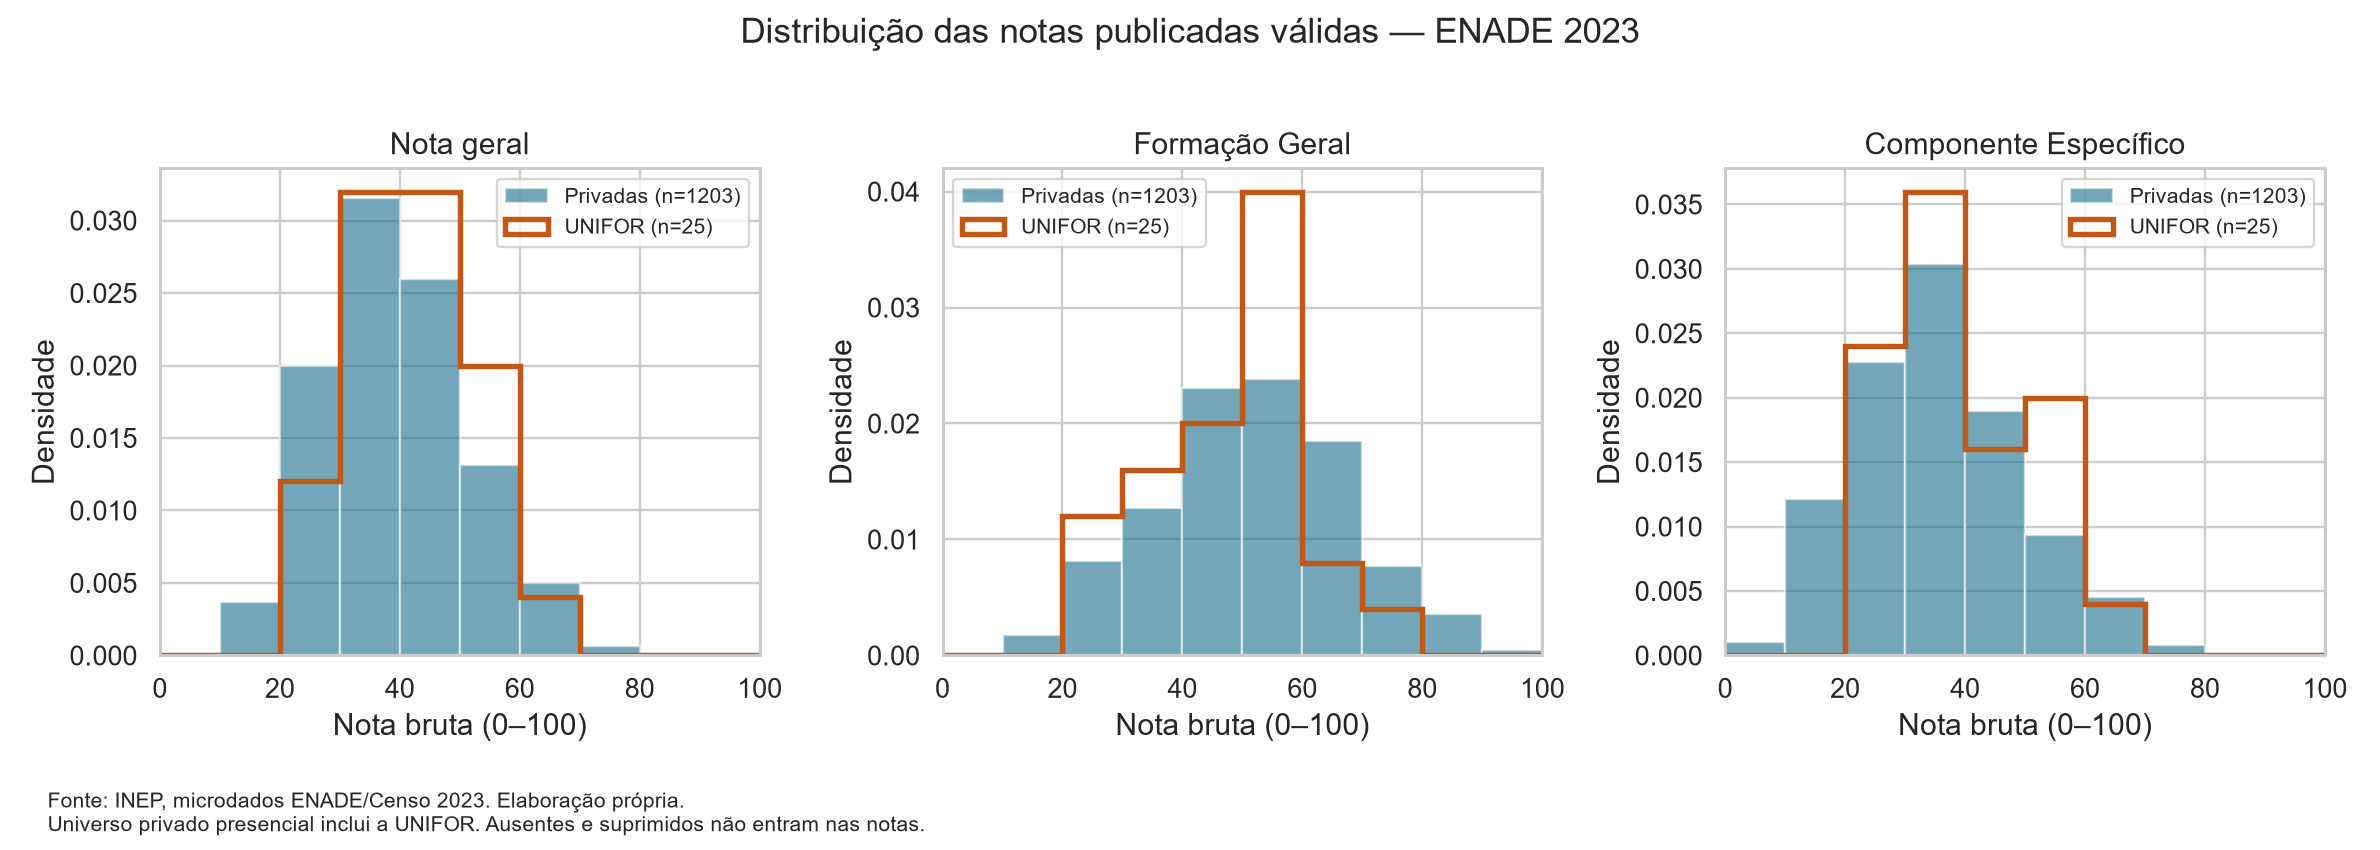

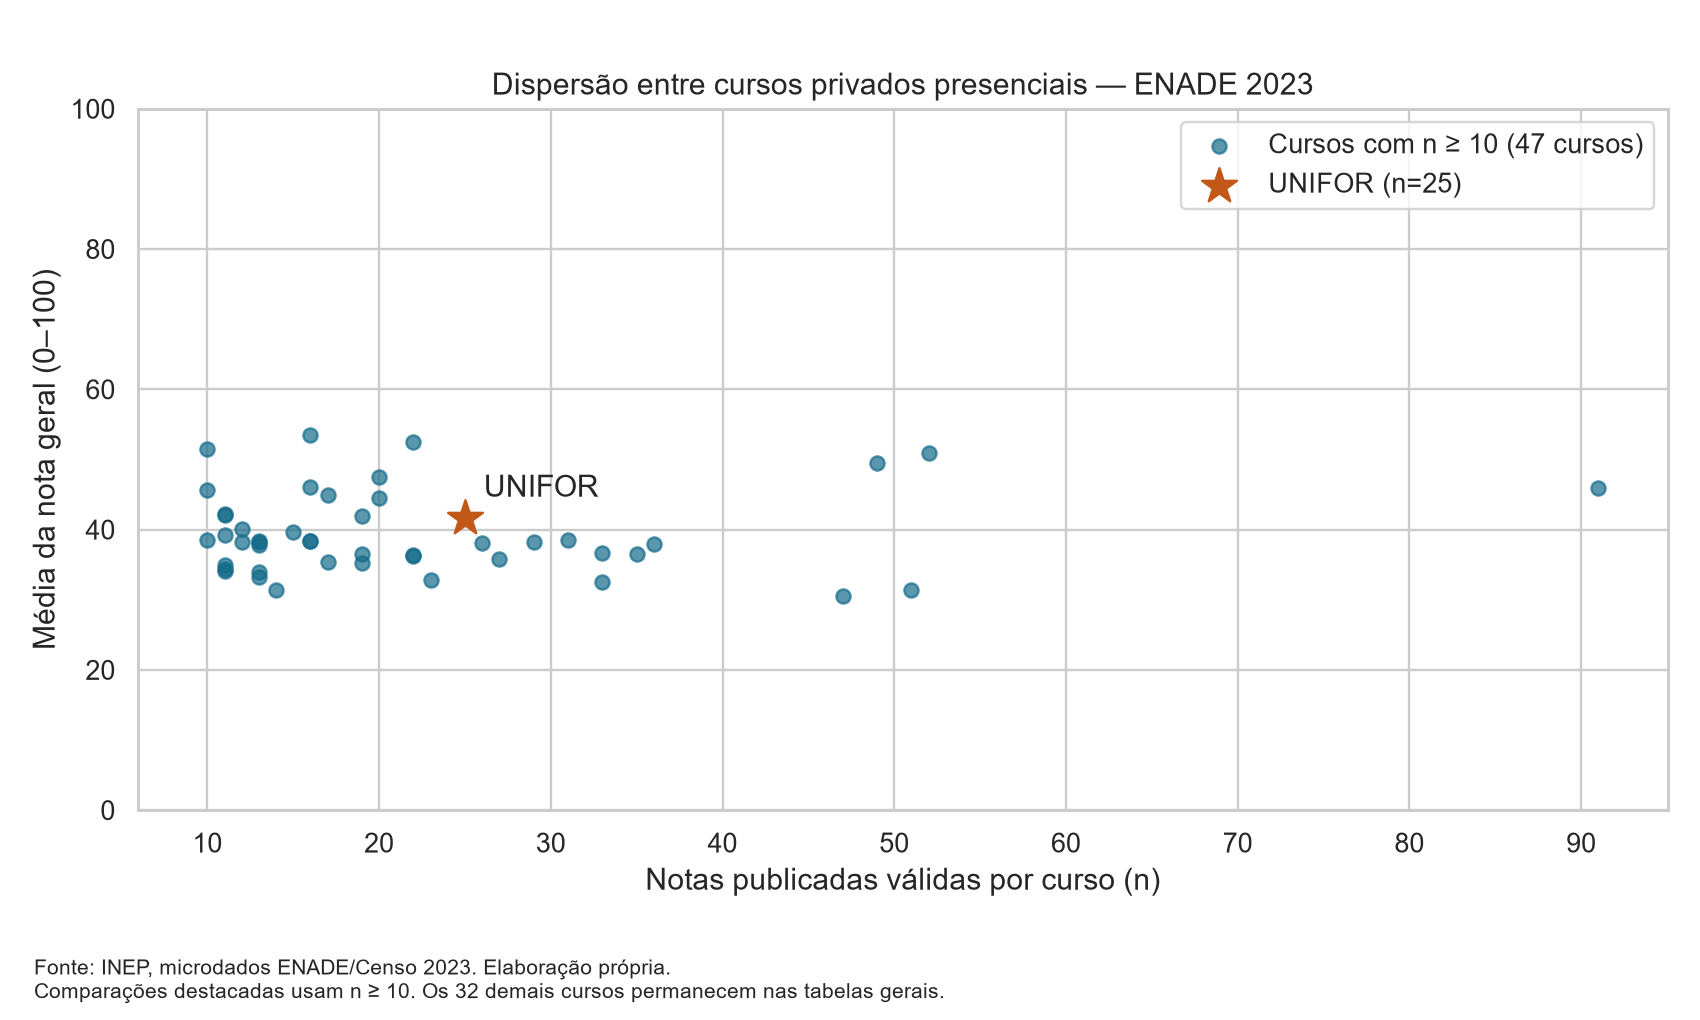

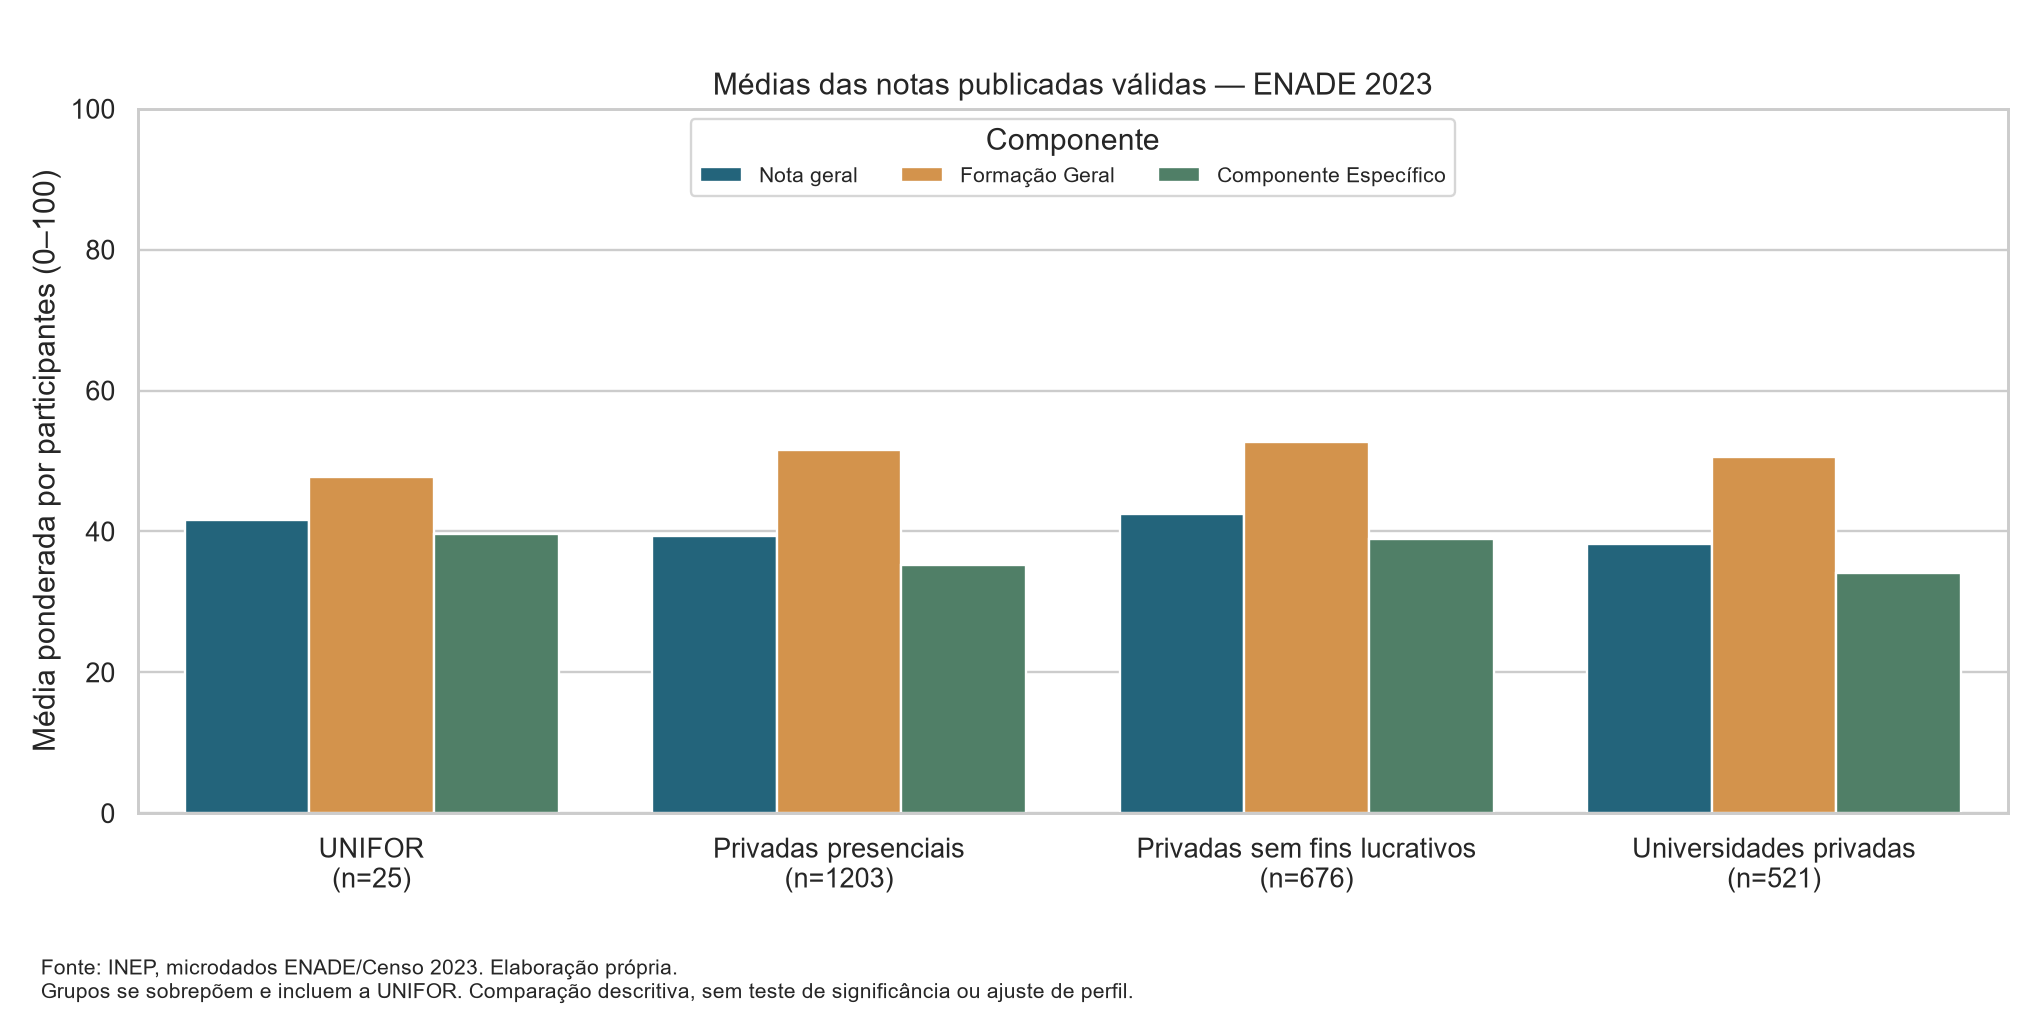

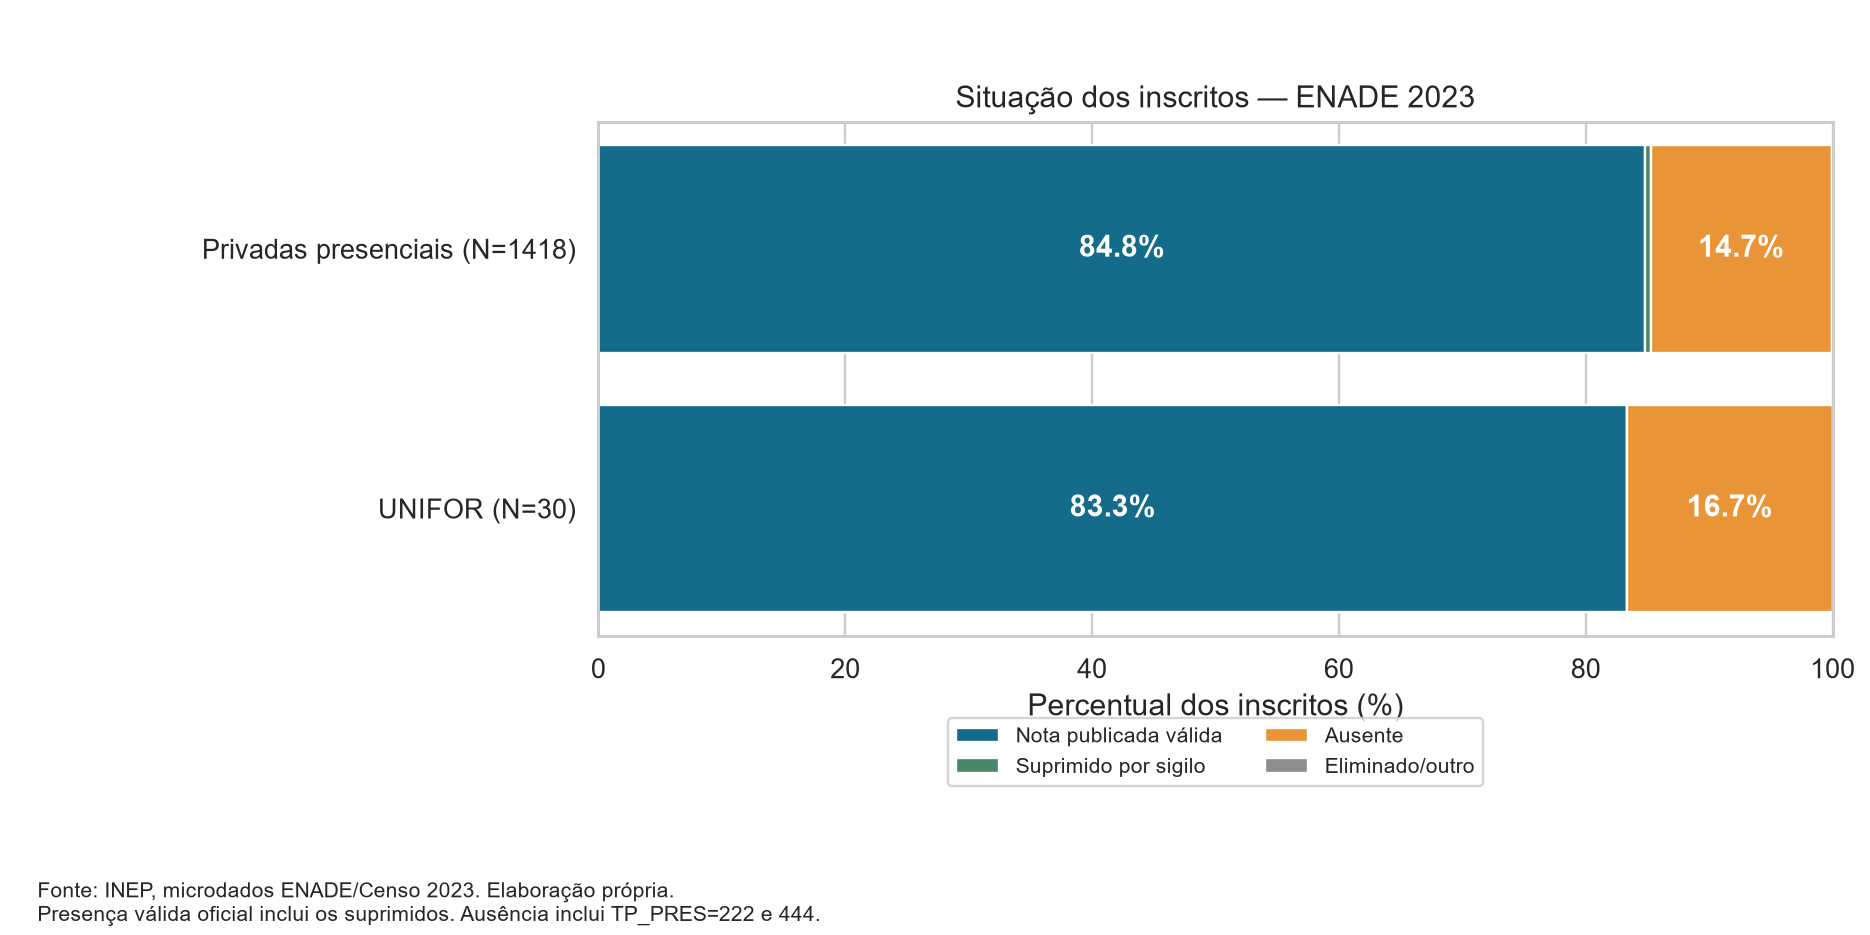

In [5]:
from IPython.display import Image, display
for nome in resultado['validacao']['graficos']:
    display(Image(filename=str(ROOT / 'resultados/graficos' / nome)))

## Verificação e reprodução

Cada média, mediana e desvio-padrão dos grupos é conferido pela biblioteca
`statistics` e as médias são reconciliadas com somas/contagens por curso.
As médias de cada curso também são verificadas independentemente.
Tabelas são relidas e comparadas; hashes vinculam entradas e saídas.
Veja docs/analise_2023.md e resultados/tabelas/validacao_analise_2023.json.
Execute todas as células com o kernel **Python (projeto-enade)**.
As conclusões descritivas validadas constam no relatório; não se faz imputação,
reidentificação nem comparação com dados de 2021.

# Aprofundamento — TASK 09–11

FG, CE, respostas e acertos são lidos juntos no arq3. Os questionários permanecem separados. Nenhuma junção individual é feita entre arquivos. O referencial detalhado exclui a UNIFOR (1.178 notas); o universo privado de 1.203 notas permanece nas tabelas institucionais.

**Divergência documental:** o XLSX local descreve pesos 60/40 e 85/15. A [NT 12/2024 do INEP](https://download.inep.gov.br/educacao_superior/enade/notas_tecnicas/2024/nota_tecnica_12_calculo_nota_final_enade_2023.pdf) determina FG 65/35 e CE 90/10. Esses pesos reproduzem as notas dentro do arredondamento; os valores oficiais não são substituídos.

In [6]:
from aprofundar_2023 import analyze as aprofundar
aprofundado = aprofundar(ROOT)

FASE 1 APROVADA: filtros, chaves, notas, sigilo, UNIFOR, CSVs e ZIPs.


Aprofundamento aprovado: 1203 pares; 9 FG + 24 CE válidos; 5 marginais socioeconômicas; 14 arquivos de figuras.


## Médias, dispersão e partes da prova
Média, mediana, quartis e DP amostral. A menor FG total da UNIFOR convive com FG objetiva maior e FG discursiva menor. A descrição localiza um resultado relativo; não diagnostica sua causa.

In [7]:
display(aprofundado['componentes'].round(3))
display(aprofundado['diferencas'].round(3))

,grupo,variavel,n,media,mediana,dp_amostral,q1,q3
0,UNIFOR,NT_GER,25,41.656,41.20,9.301,34.400,48.500
1,UNIFOR,NT_FG,25,47.776,50.60,12.374,38.600,56.600
2,UNIFOR,NT_CE,25,39.600,38.00,10.721,32.000,47.000
3,UNIFOR,NT_OBJ_FG,25,57.344,55.60,15.629,44.400,66.700
4,UNIFOR,NT_DIS_FG,25,29.996,30.90,25.219,0.000,48.000
5,UNIFOR,NT_OBJ_CE,25,42.012,41.70,11.403,33.300,50.000
6,UNIFOR,NT_DIS_CE,25,17.800,20.00,14.796,0.000,30.000
7,privado_presencial,NT_GER,1203,39.326,38.60,11.985,30.500,47.200
8,privado_presencial,NT_FG,1203,51.550,51.20,15.946,40.900,62.450
9,privado_presencial,NT_CE,1203,35.234,33.80,13.496,26.300,44.200


,grupo_referencia,variavel,n_unifor,n_referencia,media_unifor,media_referencia,diferenca_pontos
0,privado_presencial,NT_GER,25,1203,41.656,39.326,2.330
1,privado_presencial,NT_FG,25,1203,47.776,51.550,-3.774
2,privado_presencial,NT_CE,25,1203,39.600,35.234,4.366
3,privado_presencial,NT_OBJ_FG,25,1203,57.344,55.239,2.105
4,privado_presencial,NT_DIS_FG,25,1203,29.996,44.695,-14.699
5,privado_presencial,NT_OBJ_CE,25,1203,42.012,37.483,4.529
6,privado_presencial,NT_DIS_CE,25,1203,17.800,14.904,2.896
7,sem_fins_lucrativos,NT_GER,25,676,41.656,42.440,-0.784
8,sem_fins_lucrativos,NT_FG,25,676,47.776,52.737,-4.961
9,sem_fins_lucrativos,NT_CE,25,676,39.600,38.989,0.611


## Correlação FG × CE no próprio arq3
Pearson com pares completos, conferido pela fórmula de covariância. A UNIFOR tem apenas 25 pares. Não há teste de significância ou comparação inferencial entre coeficientes. Associação não implica causalidade.

In [8]:
display(aprofundado['correlacoes'].round(4))

,grupo,metodo,n_pares,r_fg_ce,nivel
0,UNIFOR,Pearson,25,0.2508,individual_mesmo_arq3
1,privado_presencial,Pearson,1203,0.3132,individual_mesmo_arq3
2,sem_fins_lucrativos,Pearson,676,0.2994,individual_mesmo_arq3
3,universidades_privadas,Pearson,521,0.2910,individual_mesmo_arq3
4,privado_sem_unifor,Pearson,1178,0.3162,individual_mesmo_arq3


## Questões objetivas: validação e percentuais
Vetores são strings, preservando zeros iniciais. Acertos são conferidos contra escolha/gabarito no mesmo registro e reconciliados com a nota objetiva. Os nove itens FG são válidos; cinco dos 29 CE são excluídos por discriminação (Q17/18/19/25/34), sem denominador ou percentual. A sequência do [gabarito oficial da área](https://download.inep.gov.br/enade/provas_e_gabaritos/2023_GB_engenharia_da_computacao.pdf) confirma FG Q1–9 e CE Q10–38. Não se atribuem competências ou equivalência com outras provas. Discursivas são notas de correção, não taxas de acerto. Uma resposta da UNIFOR representa 4 pontos percentuais.

In [9]:
display(aprofundado['itens'].round(3))
it = aprofundado['itens'].pivot(index=['componente','questao_caderno'], columns='grupo', values='percentual_acerto')
it['diferenca_pp'] = it.UNIFOR - it.privado_sem_unifor
display(it[['UNIFOR','privado_sem_unifor','diferenca_pp']].round(3))

,grupo,componente,posicao_vetor,questao_caderno,gabarito_final,situacao,n_base_notas,n_respostas_validas,acertos,erros,excluidos,percentual_acerto
0,UNIFOR,FG,1,1,D,valido,25,25,16,9,0,64.000
1,UNIFOR,FG,2,2,D,valido,25,25,22,3,0,88.000
2,UNIFOR,FG,3,3,B,valido,25,25,18,7,0,72.000
3,UNIFOR,FG,4,4,A,valido,25,25,12,13,0,48.000
4,UNIFOR,FG,5,5,E,valido,25,25,11,14,0,44.000
...,...,...,...,...,...,...,...,...,...,...,...,...
185,privado_sem_unifor,CE,25,34,9,excluido_discriminacao,1178,0,0,0,1178,NaN
186,privado_sem_unifor,CE,26,35,E,valido,1178,1178,469,709,0,39.813
187,privado_sem_unifor,CE,27,36,C,valido,1178,1178,589,589,0,50.000
188,privado_sem_unifor,CE,28,37,C,valido,1178,1178,315,863,0,26.740


grupo                       UNIFOR  privado_sem_unifor  diferenca_pp
componente questao_caderno                                          
CE         10                 40.0              30.900         9.100
           11                 24.0              30.645        -6.645
           12                 20.0              16.978         3.022
           13                 36.0              22.071        13.929
           14                  8.0              15.705        -7.705
           15                 28.0              29.032        -1.032
           16                  4.0               5.942        -1.942
           17                  NaN                 NaN           NaN
           18                  NaN                 NaN           NaN
           19                  NaN                 NaN           NaN
           20                 48.0              42.954         5.046
           21                 52.0              42.530         9.470
           22                 40.0              40.577        -0.577
           23                 60.0              34.211        25.789
           24                 56.0              39.813        16.187
           25                  NaN                 NaN           NaN
           26                 68.0              65.110         2.890
           27                 48.0              33.531        14.469
           28                 32.0              47.623       -15.623
           29                 60.0              42.954        17.046
           30                 80.0              56.706        23.294
           31                 28.0              23.514         4.486
           32                 60.0              58.744         1.256
           33                 36.0              38.710        -2.710
           34                  NaN                 NaN           NaN
           35                 44.0              39.813         4.187
           36                 52.0              50.000         2.000
           37                 20.0              26.740        -6.740
           38                 64.0              62.479         1.521
FG         1                  64.0              63.752         0.248
           2                  88.0              81.664         6.336
           3                  72.0              61.885        10.115
           4                  48.0              57.131        -9.131
           5                  44.0              47.708        -3.708
           6                  80.0              79.966         0.034
           7                  40.0              30.390         9.610
           8                  52.0              48.557         3.443
           9                  28.0              25.637         2.363

## Perfil socioeconômico: proporções marginais
Renda (arq14), trabalho exceto estágio/bolsas (arq16), escolaridade do pai (arq10), da mãe (arq11) e ensino médio (arq23). Cada proporção divide pelas respostas publicadas daquela pergunta/curso/grupo. Ausências ficam separadas. Denominadores iguais não identificam pessoas iguais. Não se filtram questionários com presença ou nota de outro arquivo. Categorias e faixas monetárias seguem 2023.

In [10]:
display(aprofundado['indicadores'].round(3))
display(aprofundado['socioeconomico'].round(3))

,grupo,variavel,indicador,categorias,contagem,n_respondentes,n_ausentes,n_arquivo,percentual
0,UNIFOR,QE_I08,Renda familiar até 3 salários mínimos,A+B,2,29,1,30,6.897
1,privado_presencial,QE_I08,Renda familiar até 3 salários mínimos,A+B,287,1284,134,1418,22.352
2,sem_fins_lucrativos,QE_I08,Renda familiar até 3 salários mínimos,A+B,108,715,40,755,15.105
3,universidades_privadas,QE_I08,Renda familiar até 3 salários mínimos,A+B,125,555,46,601,22.523
4,privado_sem_unifor,QE_I08,Renda familiar até 3 salários mínimos,A+B,285,1255,133,1388,22.709
5,UNIFOR,QE_I10,Trabalho: 40 horas semanais ou mais,E,18,29,1,30,62.069
6,privado_presencial,QE_I10,Trabalho: 40 horas semanais ou mais,E,745,1284,134,1418,58.022
7,sem_fins_lucrativos,QE_I10,Trabalho: 40 horas semanais ou mais,E,414,715,40,755,57.902
8,universidades_privadas,QE_I10,Trabalho: 40 horas semanais ou mais,E,352,555,46,601,63.423
9,privado_sem_unifor,QE_I10,Trabalho: 40 horas semanais ou mais,E,727,1255,133,1388,57.928


,grupo,variavel,arquivo,categoria,rotulo,n_arquivo,n_respondentes,n_ausentes,contagem,percentual_respondentes
0,UNIFOR,QE_I08,arq14,A,"Até 1,5 salário mínimo (até R$ 1.980,00).",30,29,1,1,3.448
1,UNIFOR,QE_I08,arq14,B,"De 1,5 a 3 salários mínimos (R$ 1.980,01 a R$ ...",30,29,1,1,3.448
2,UNIFOR,QE_I08,arq14,C,"De 3 a 4,5 salários mínimos (R$ 3.960,01 a R$ ...",30,29,1,8,27.586
3,UNIFOR,QE_I08,arq14,D,"De 4,5 a 6 salários mínimos (R$ 5.940,01 a R$ ...",30,29,1,4,13.793
4,UNIFOR,QE_I08,arq14,E,"De 6 a 10 salários mínimos (R$ 7.920,01 a R$ 1...",30,29,1,5,17.241
...,...,...,...,...,...,...,...,...,...,...
145,privado_sem_unifor,QE_I17,arq23,B,Todo em escola privada (particular).,1388,1255,133,517,41.195
146,privado_sem_unifor,QE_I17,arq23,C,Todo no exterior.,1388,1255,133,0,0.000
147,privado_sem_unifor,QE_I17,arq23,D,A maior parte em escola pública.,1388,1255,133,37,2.948
148,privado_sem_unifor,QE_I17,arq23,E,A maior parte em escola privada (particular).,1388,1255,133,55,4.382


## Complemento fora do relatório: associação ecológica
Depois de agregar separadamente por curso, correlacionam-se proporções de perfil e média geral nos cursos com pelo menos 10 notas e 10 respostas: Pearson com peso igual por curso, 47 cursos por indicador. Não é efeito individual, ajuste de desempenho ou evidência causal. Os limiares são escolhas descritivas. São correlações exploratórias sem testes múltiplos; não explicam o resultado individual da UNIFOR.

In [11]:
display(aprofundado['ecologicas'].round(4))

,variavel,indicador,n_cursos,metodo,r_agregado,unidade,peso,min_notas_respostas
0,QE_I08,Renda familiar até 3 salários mínimos,47,Pearson,-0.4135,curso,igual_por_curso,10
1,QE_I10,Trabalho: 40 horas semanais ou mais,47,Pearson,-0.0688,curso,igual_por_curso,10
2,QE_I04,Pai com graduação ou pós-graduação,47,Pearson,0.2911,curso,igual_por_curso,10
3,QE_I05,Mãe com graduação ou pós-graduação,47,Pearson,0.3434,curso,igual_por_curso,10
4,QE_I17,Ensino médio todo em escola pública,47,Pearson,-0.3983,curso,igual_por_curso,10


## Figuras com fontes e escalas
Sete gráficos em PNG 300 dpi e PDF vetorial. O relatório seleciona seis e mantém o boxplot neste notebook para evitar redundância.

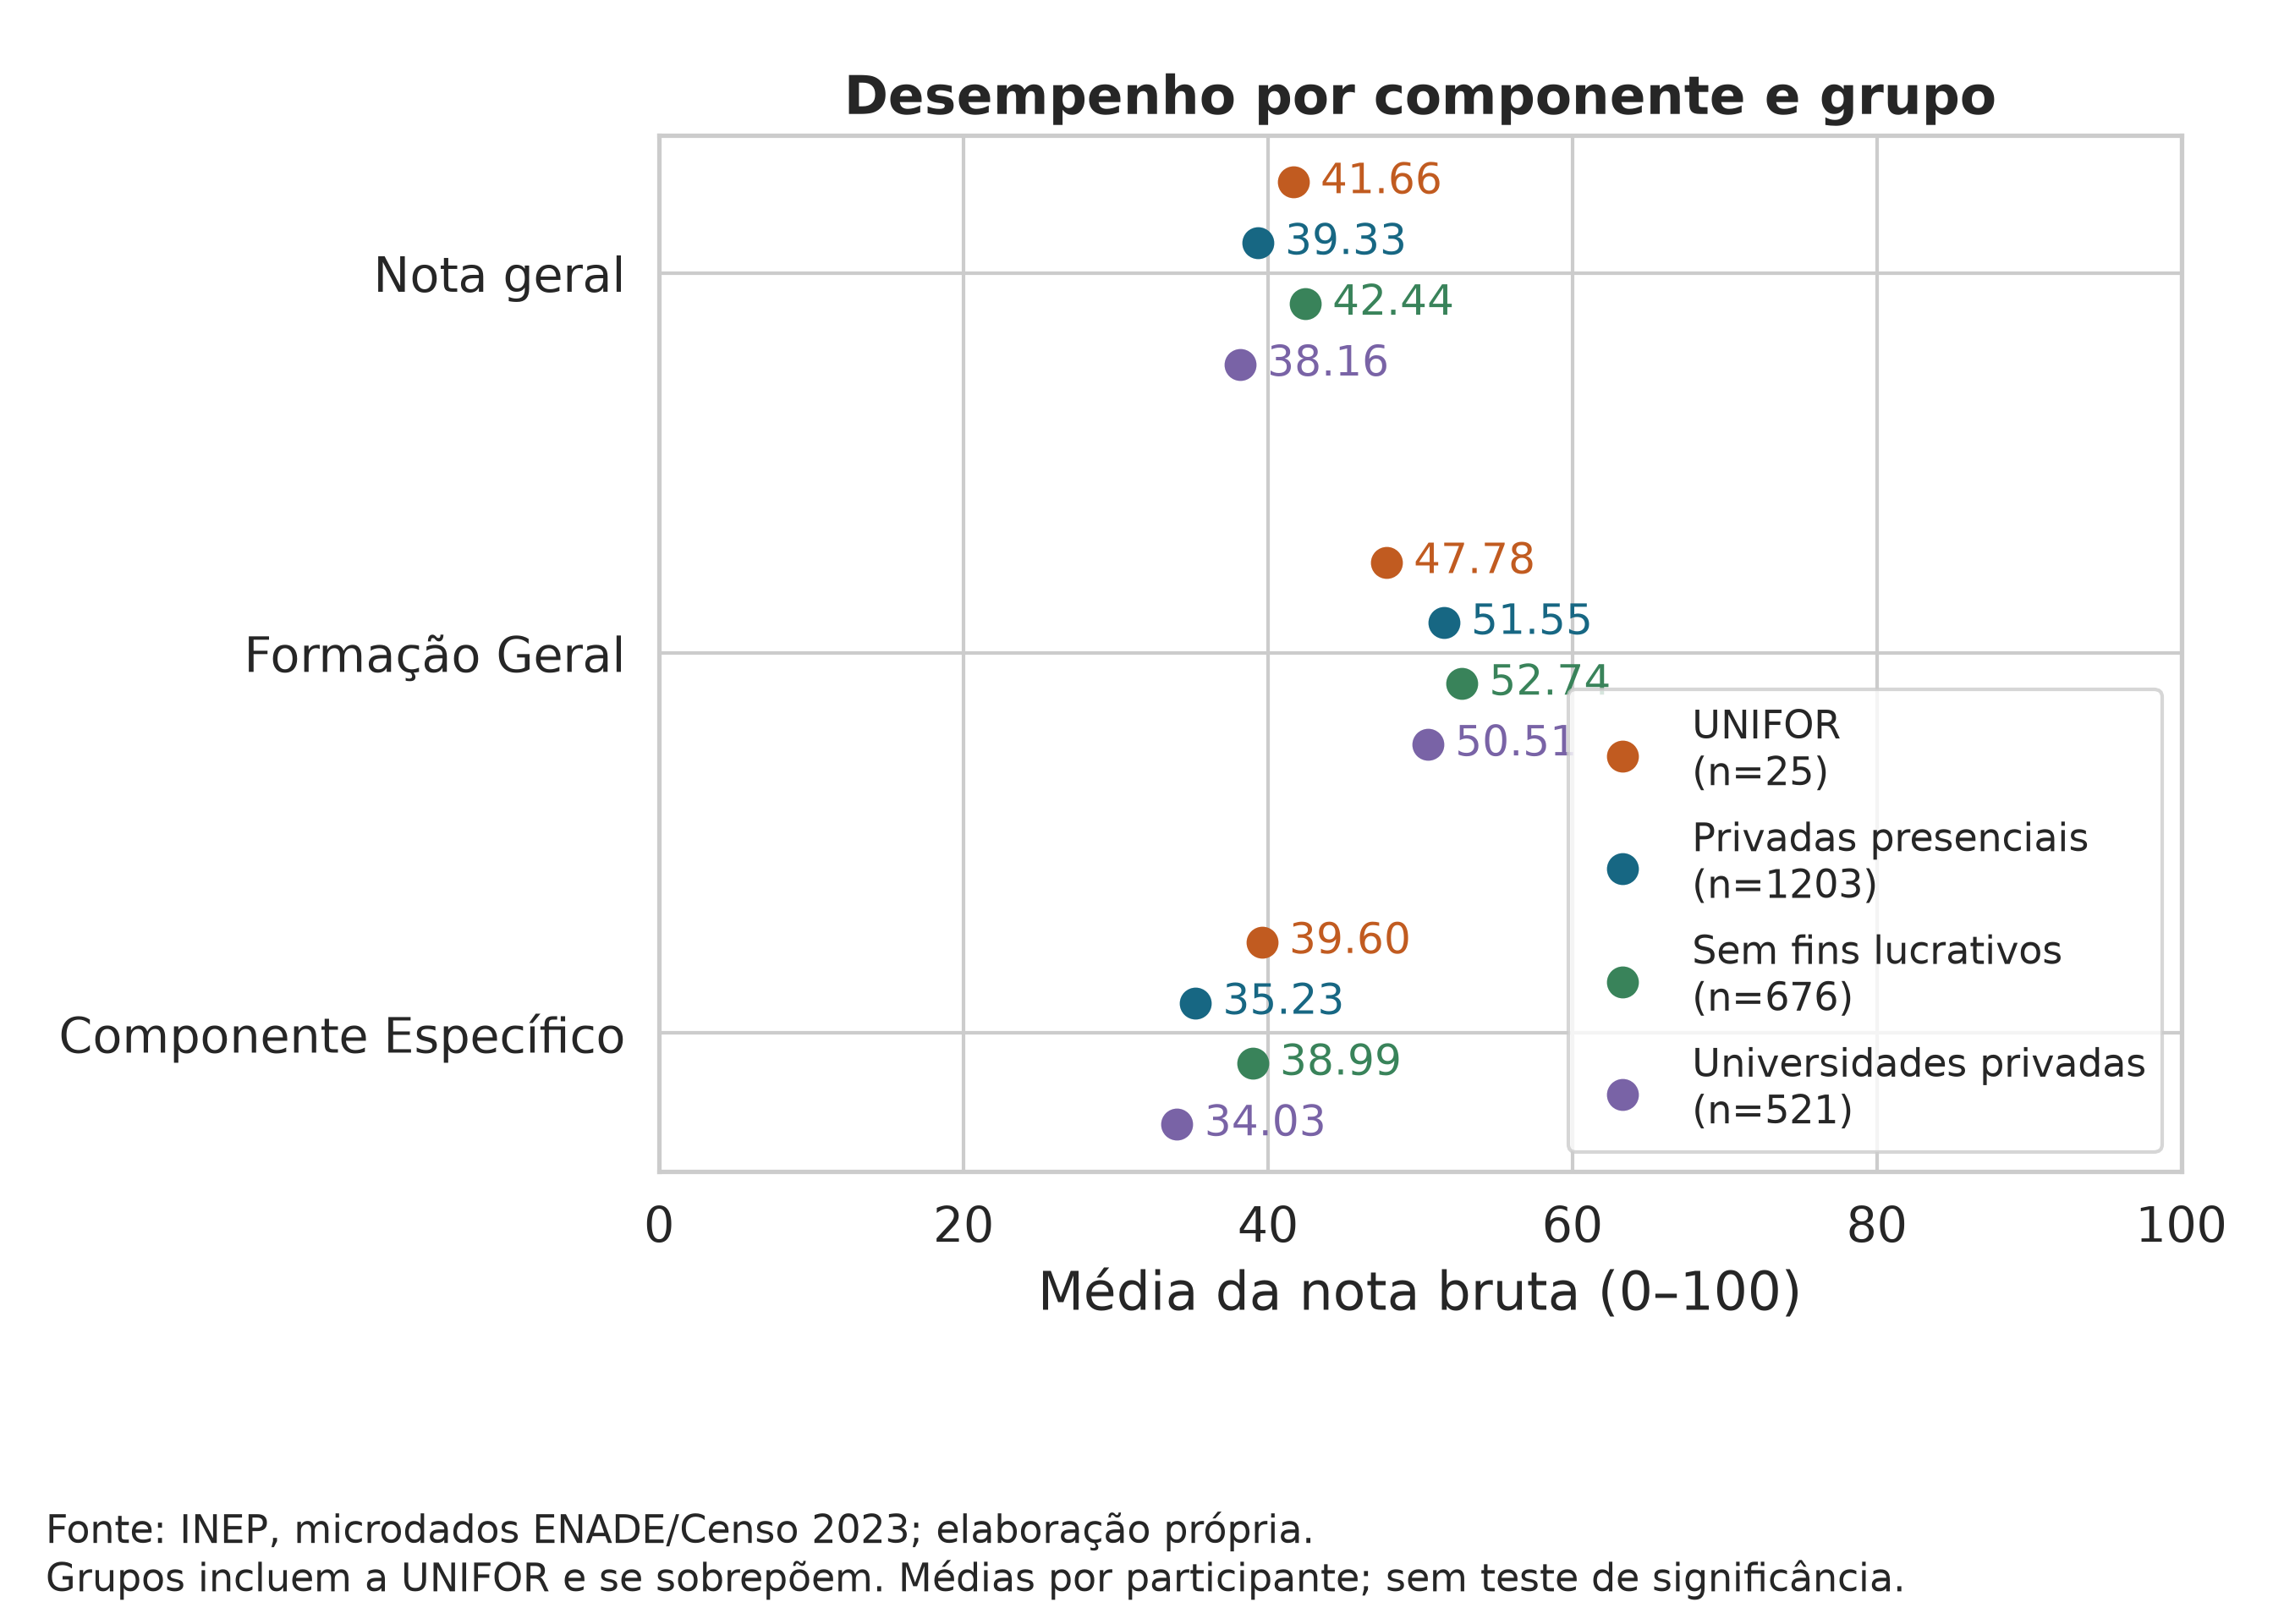

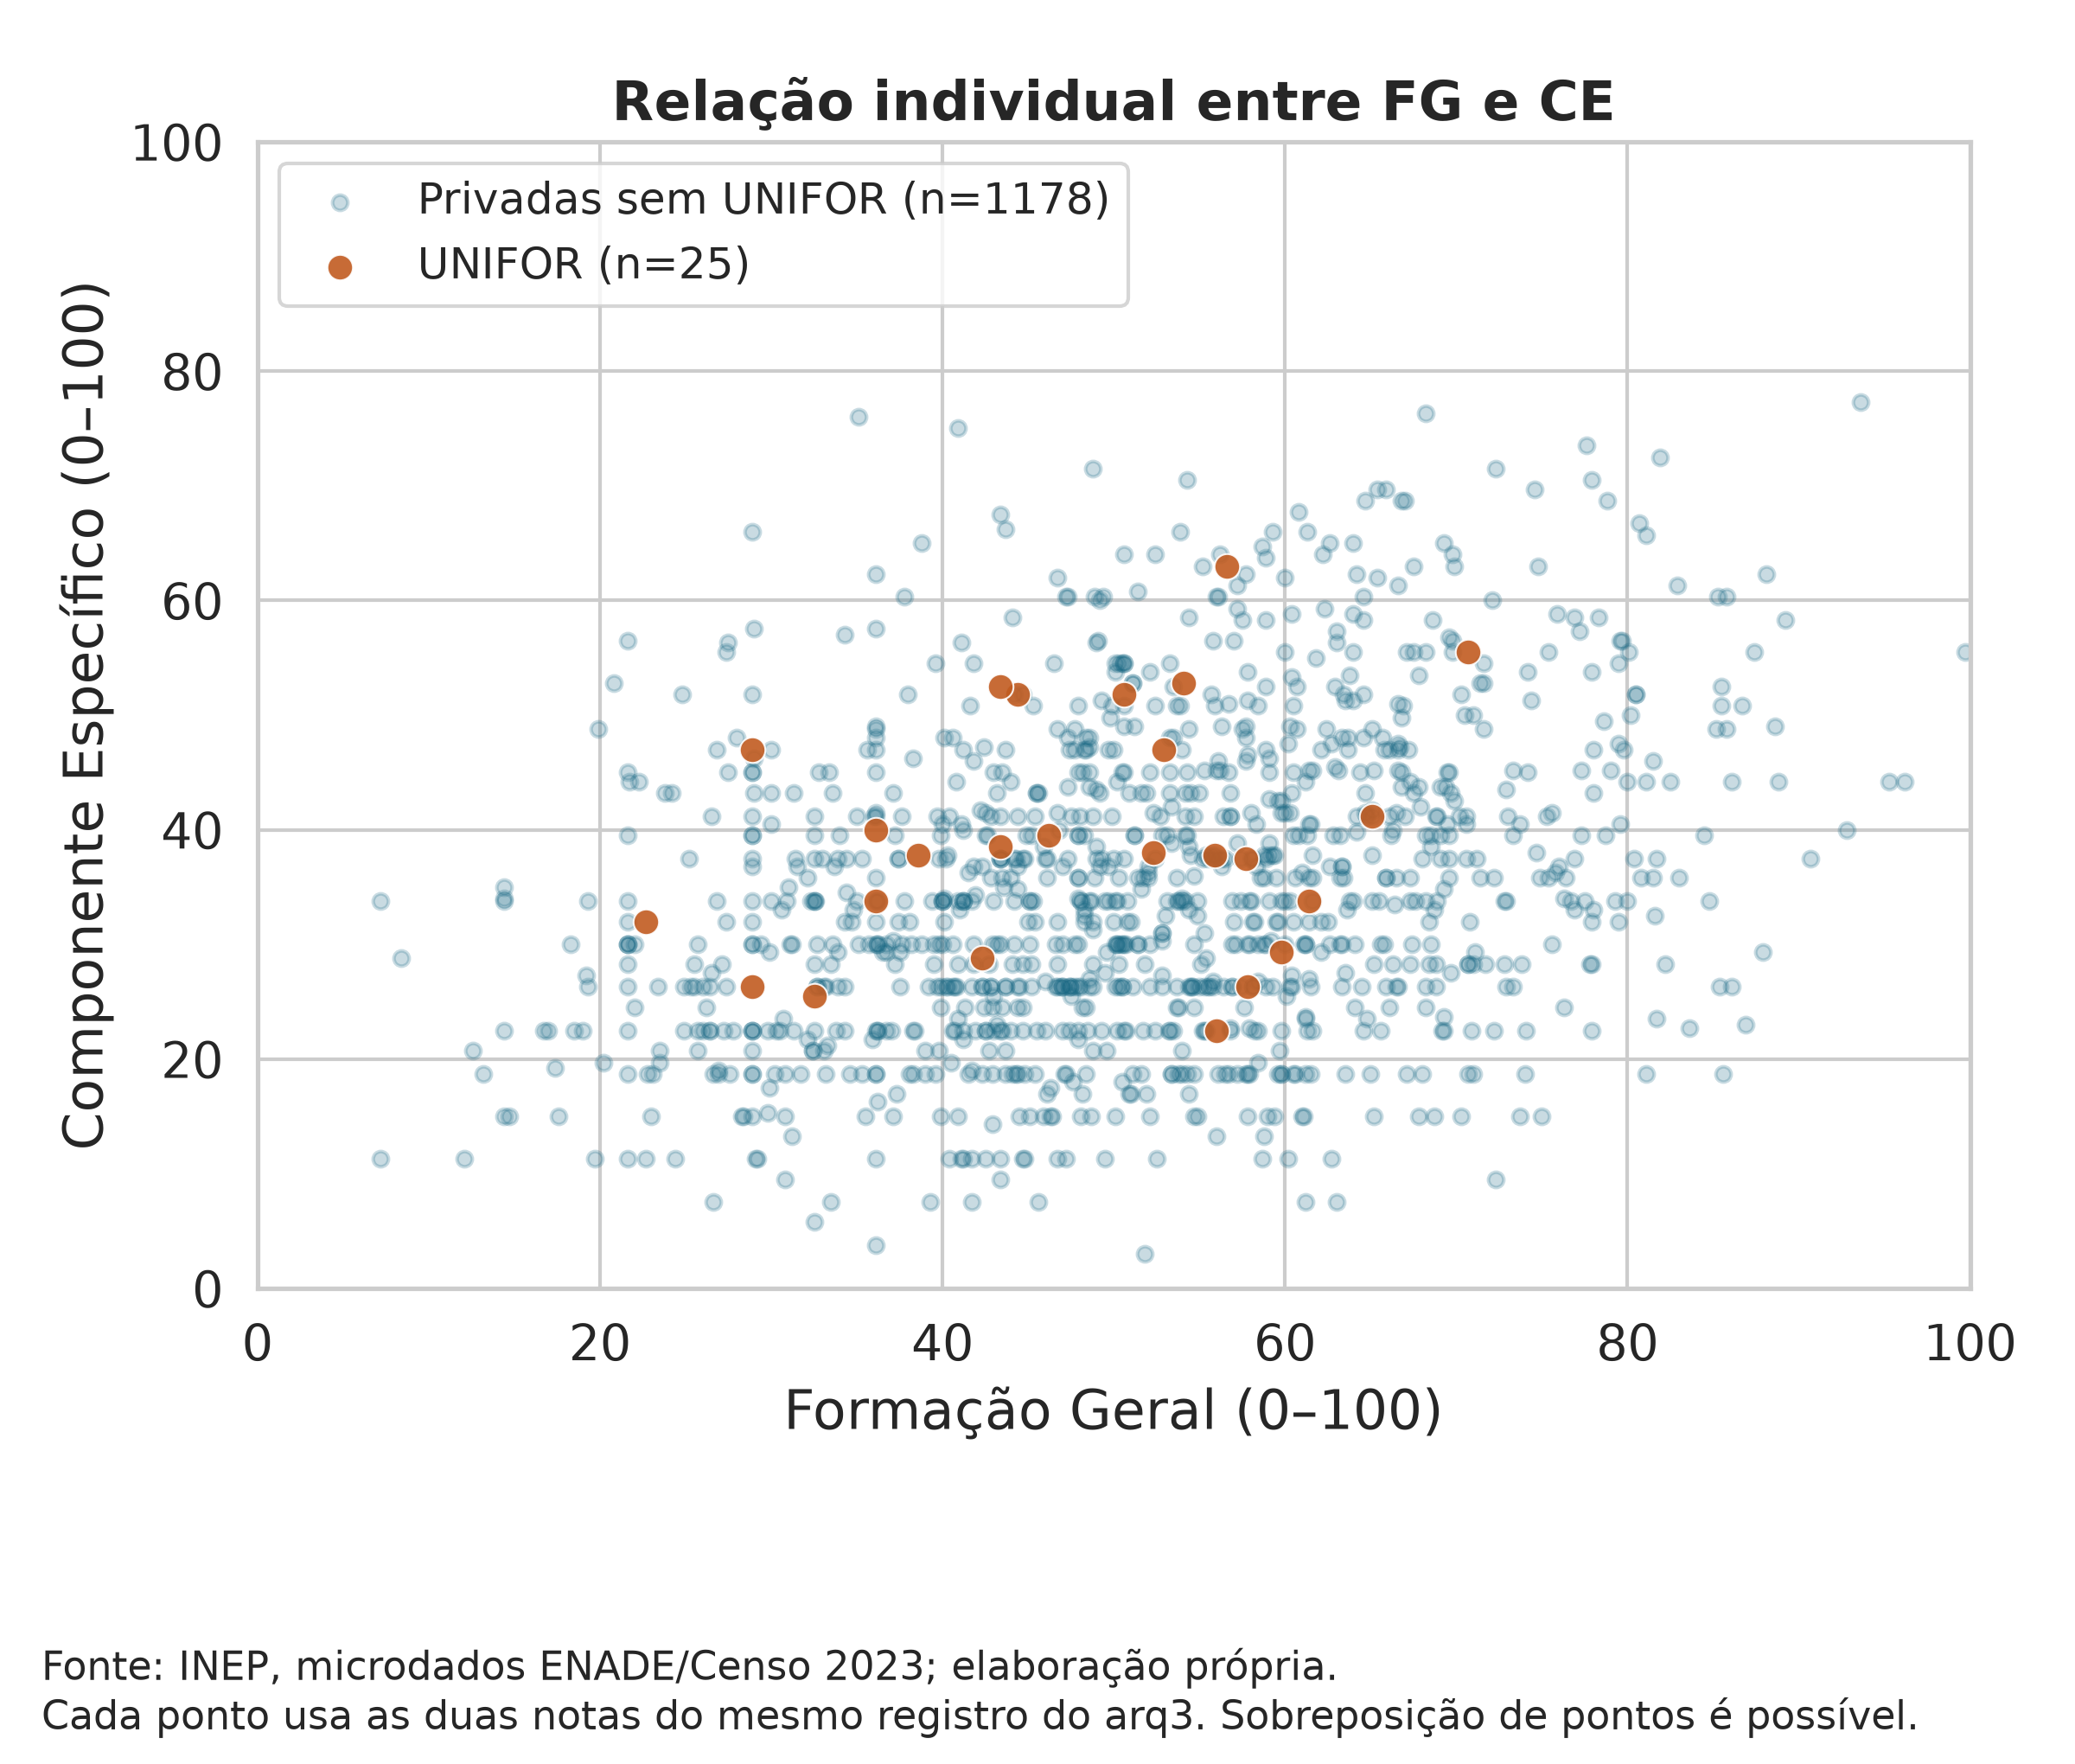

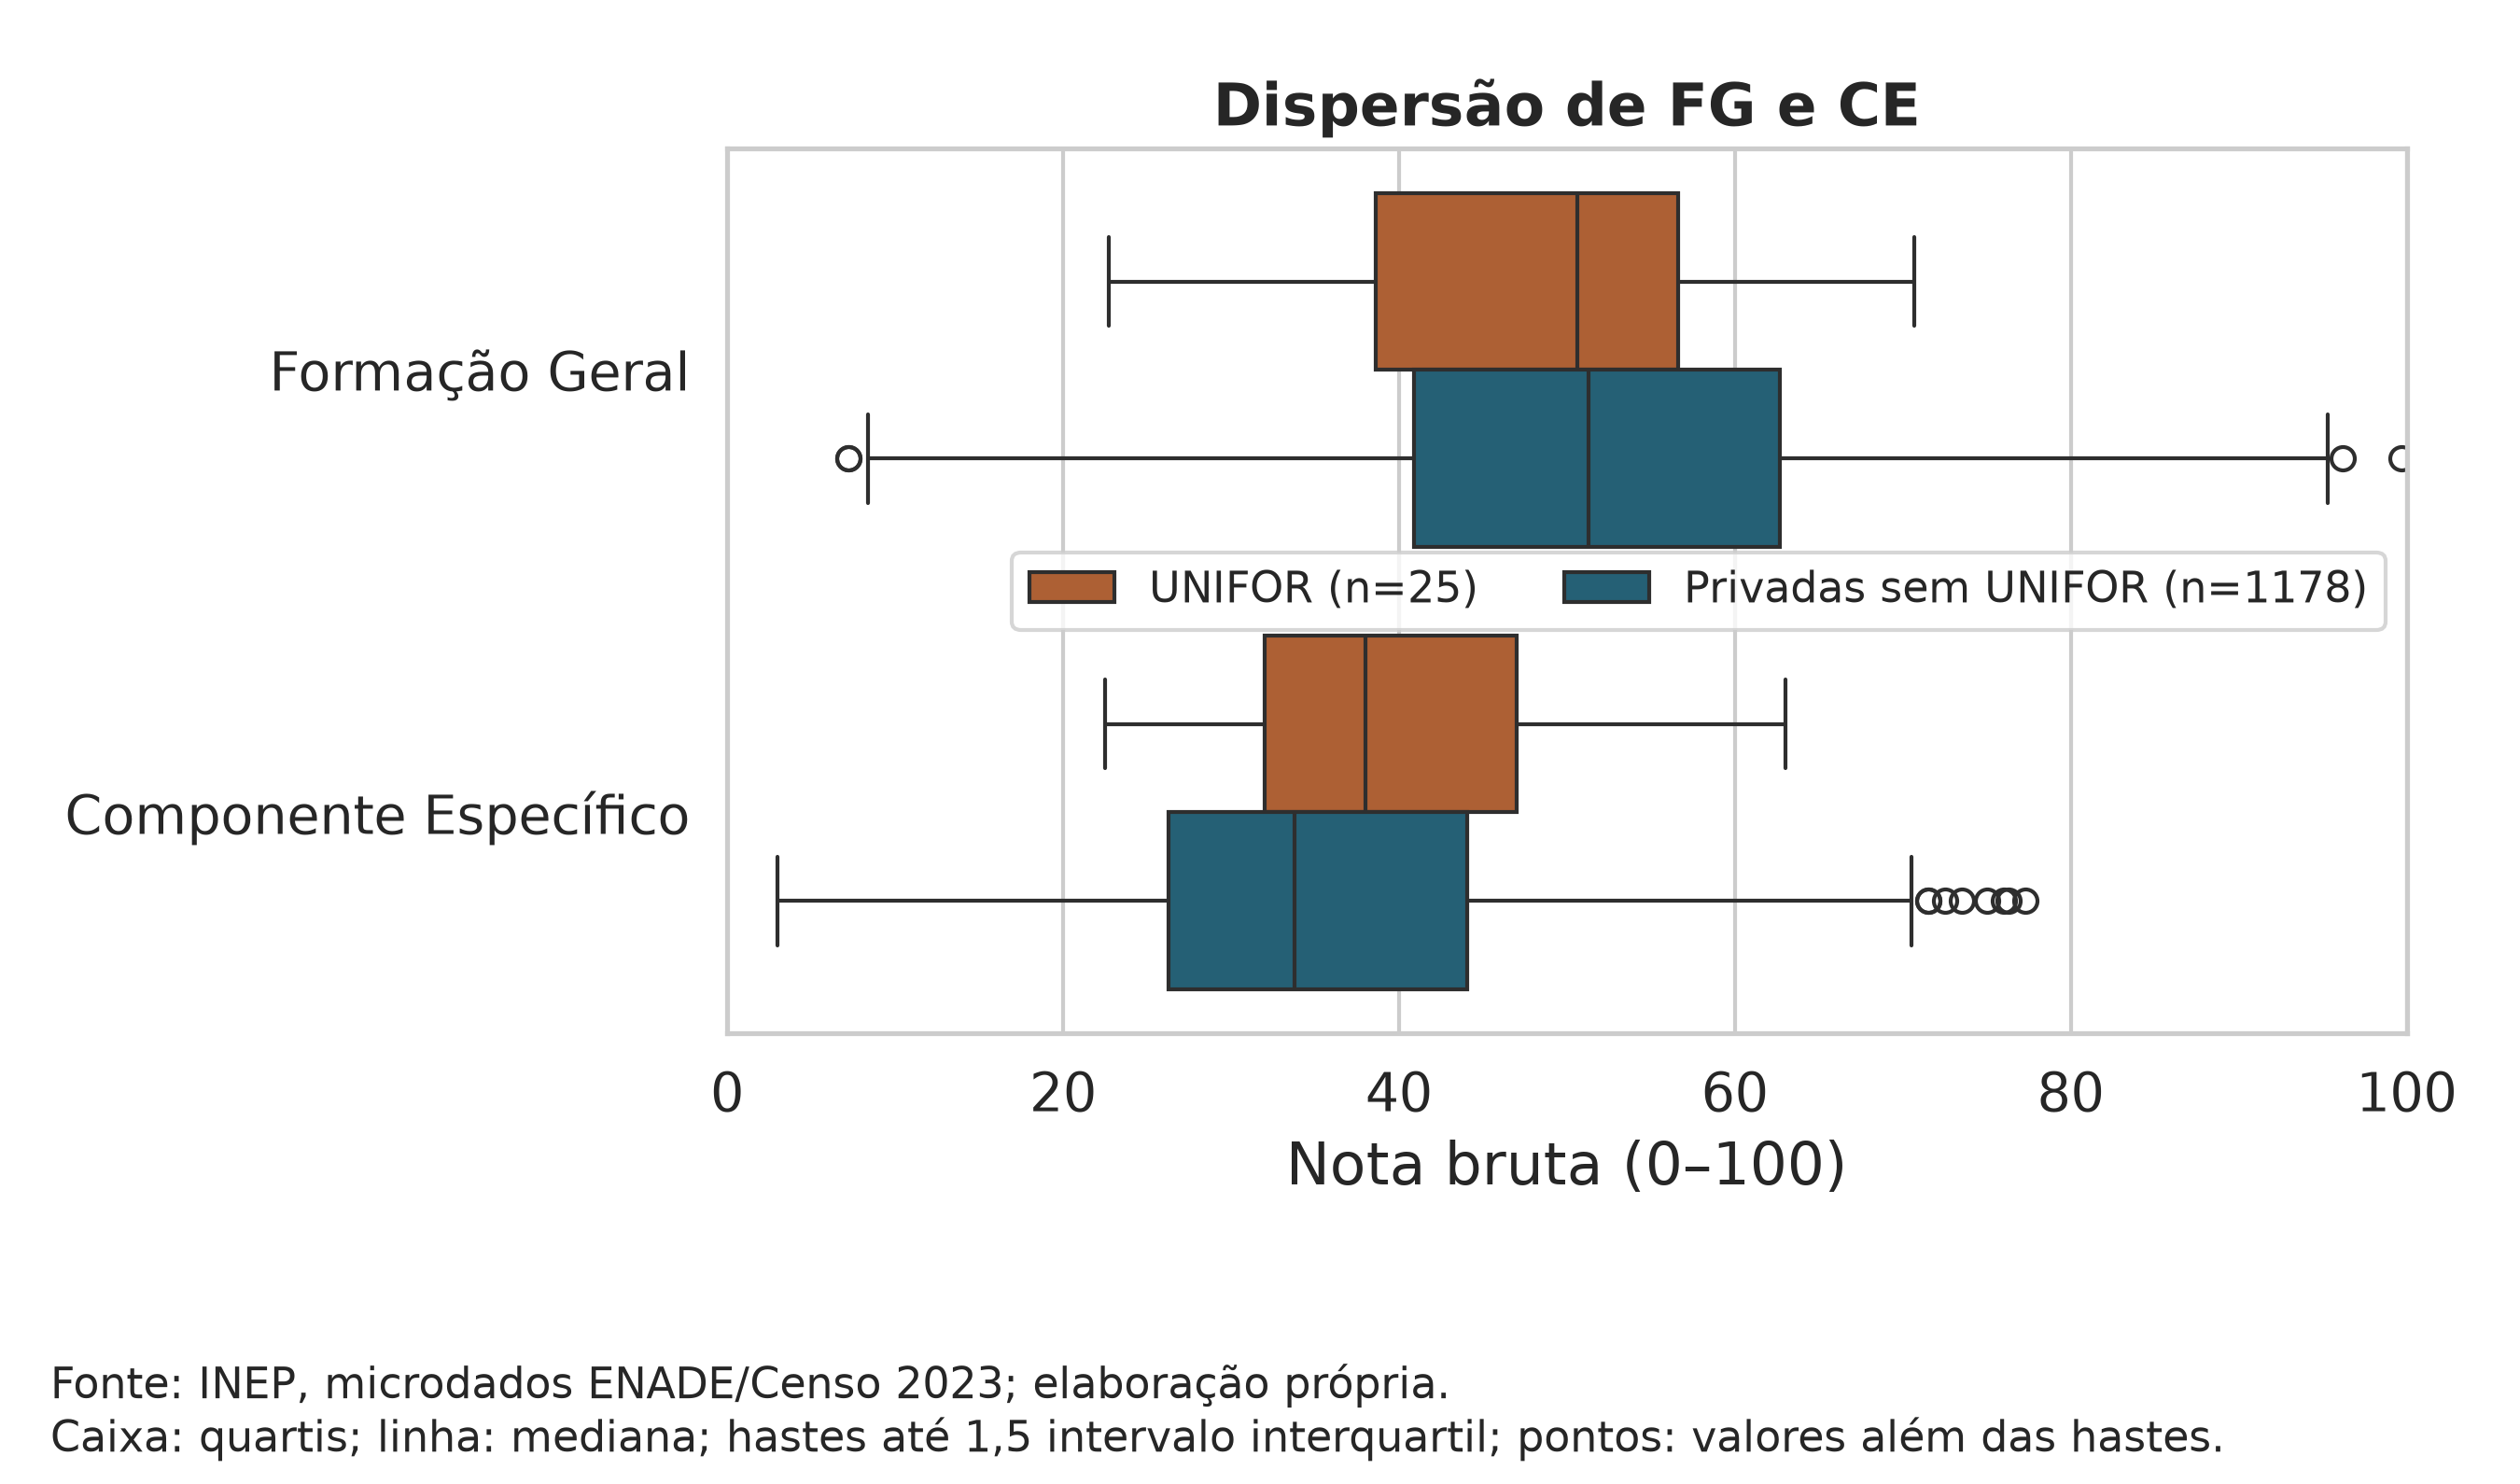

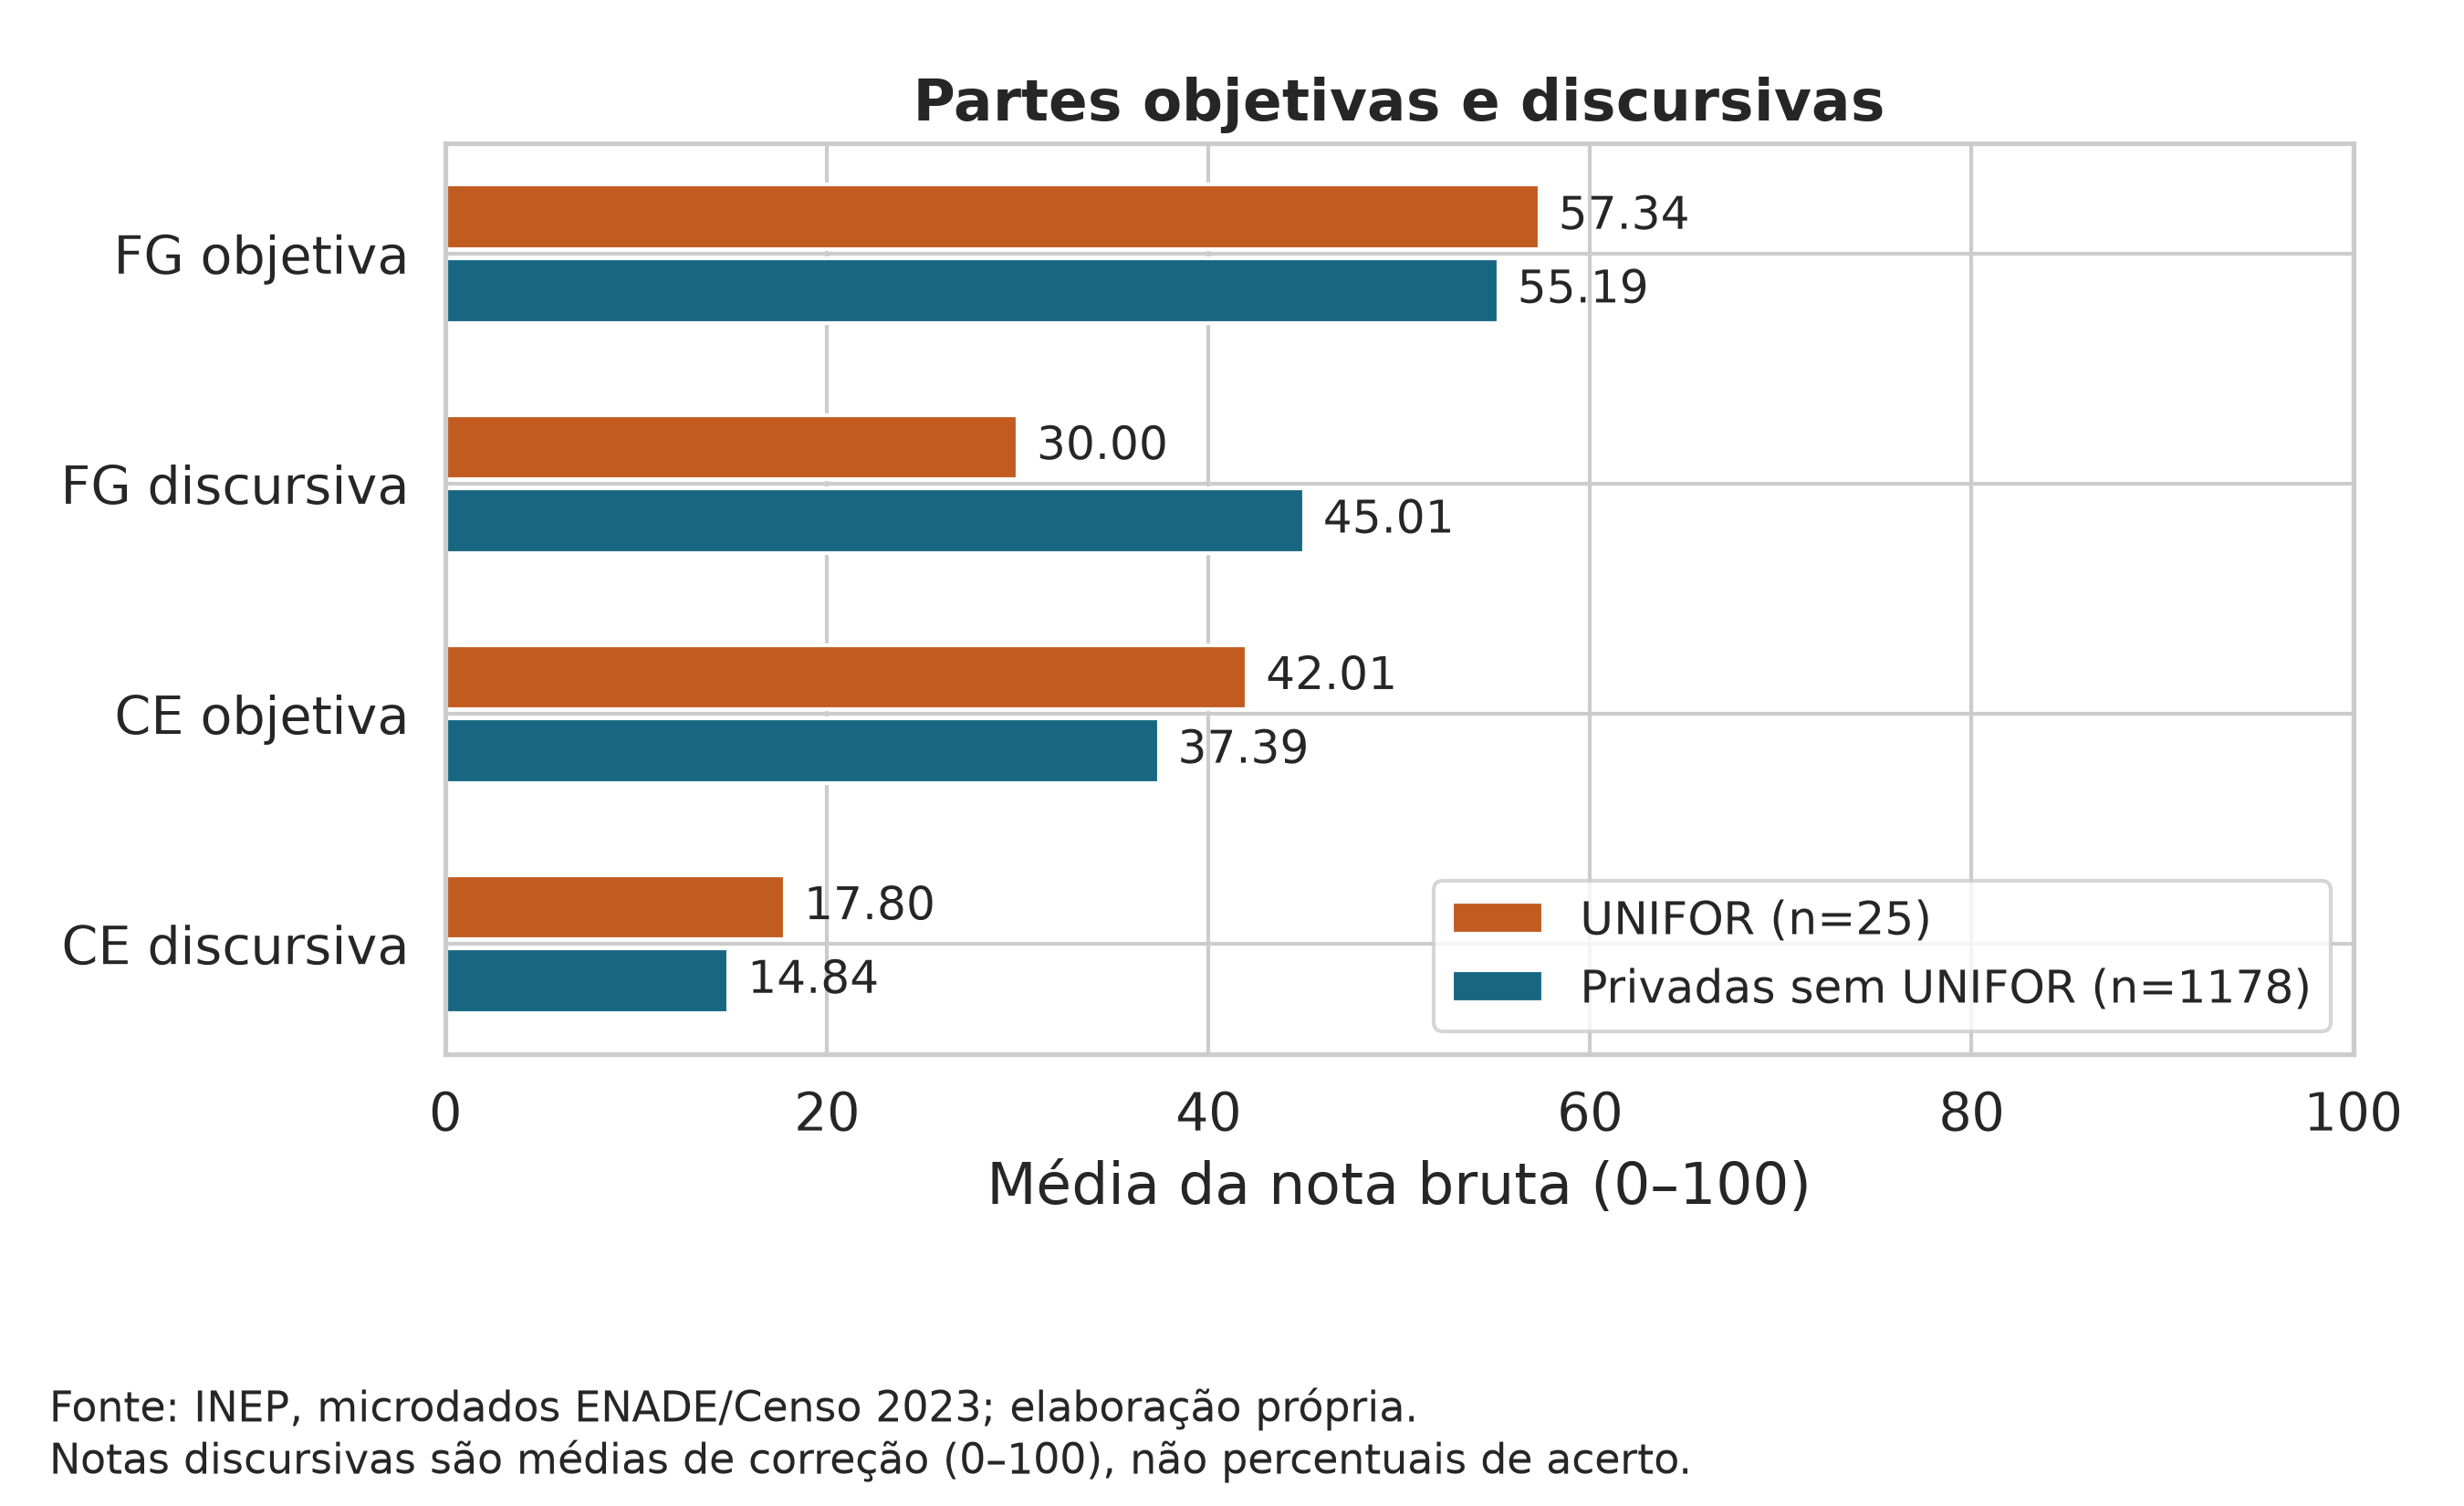

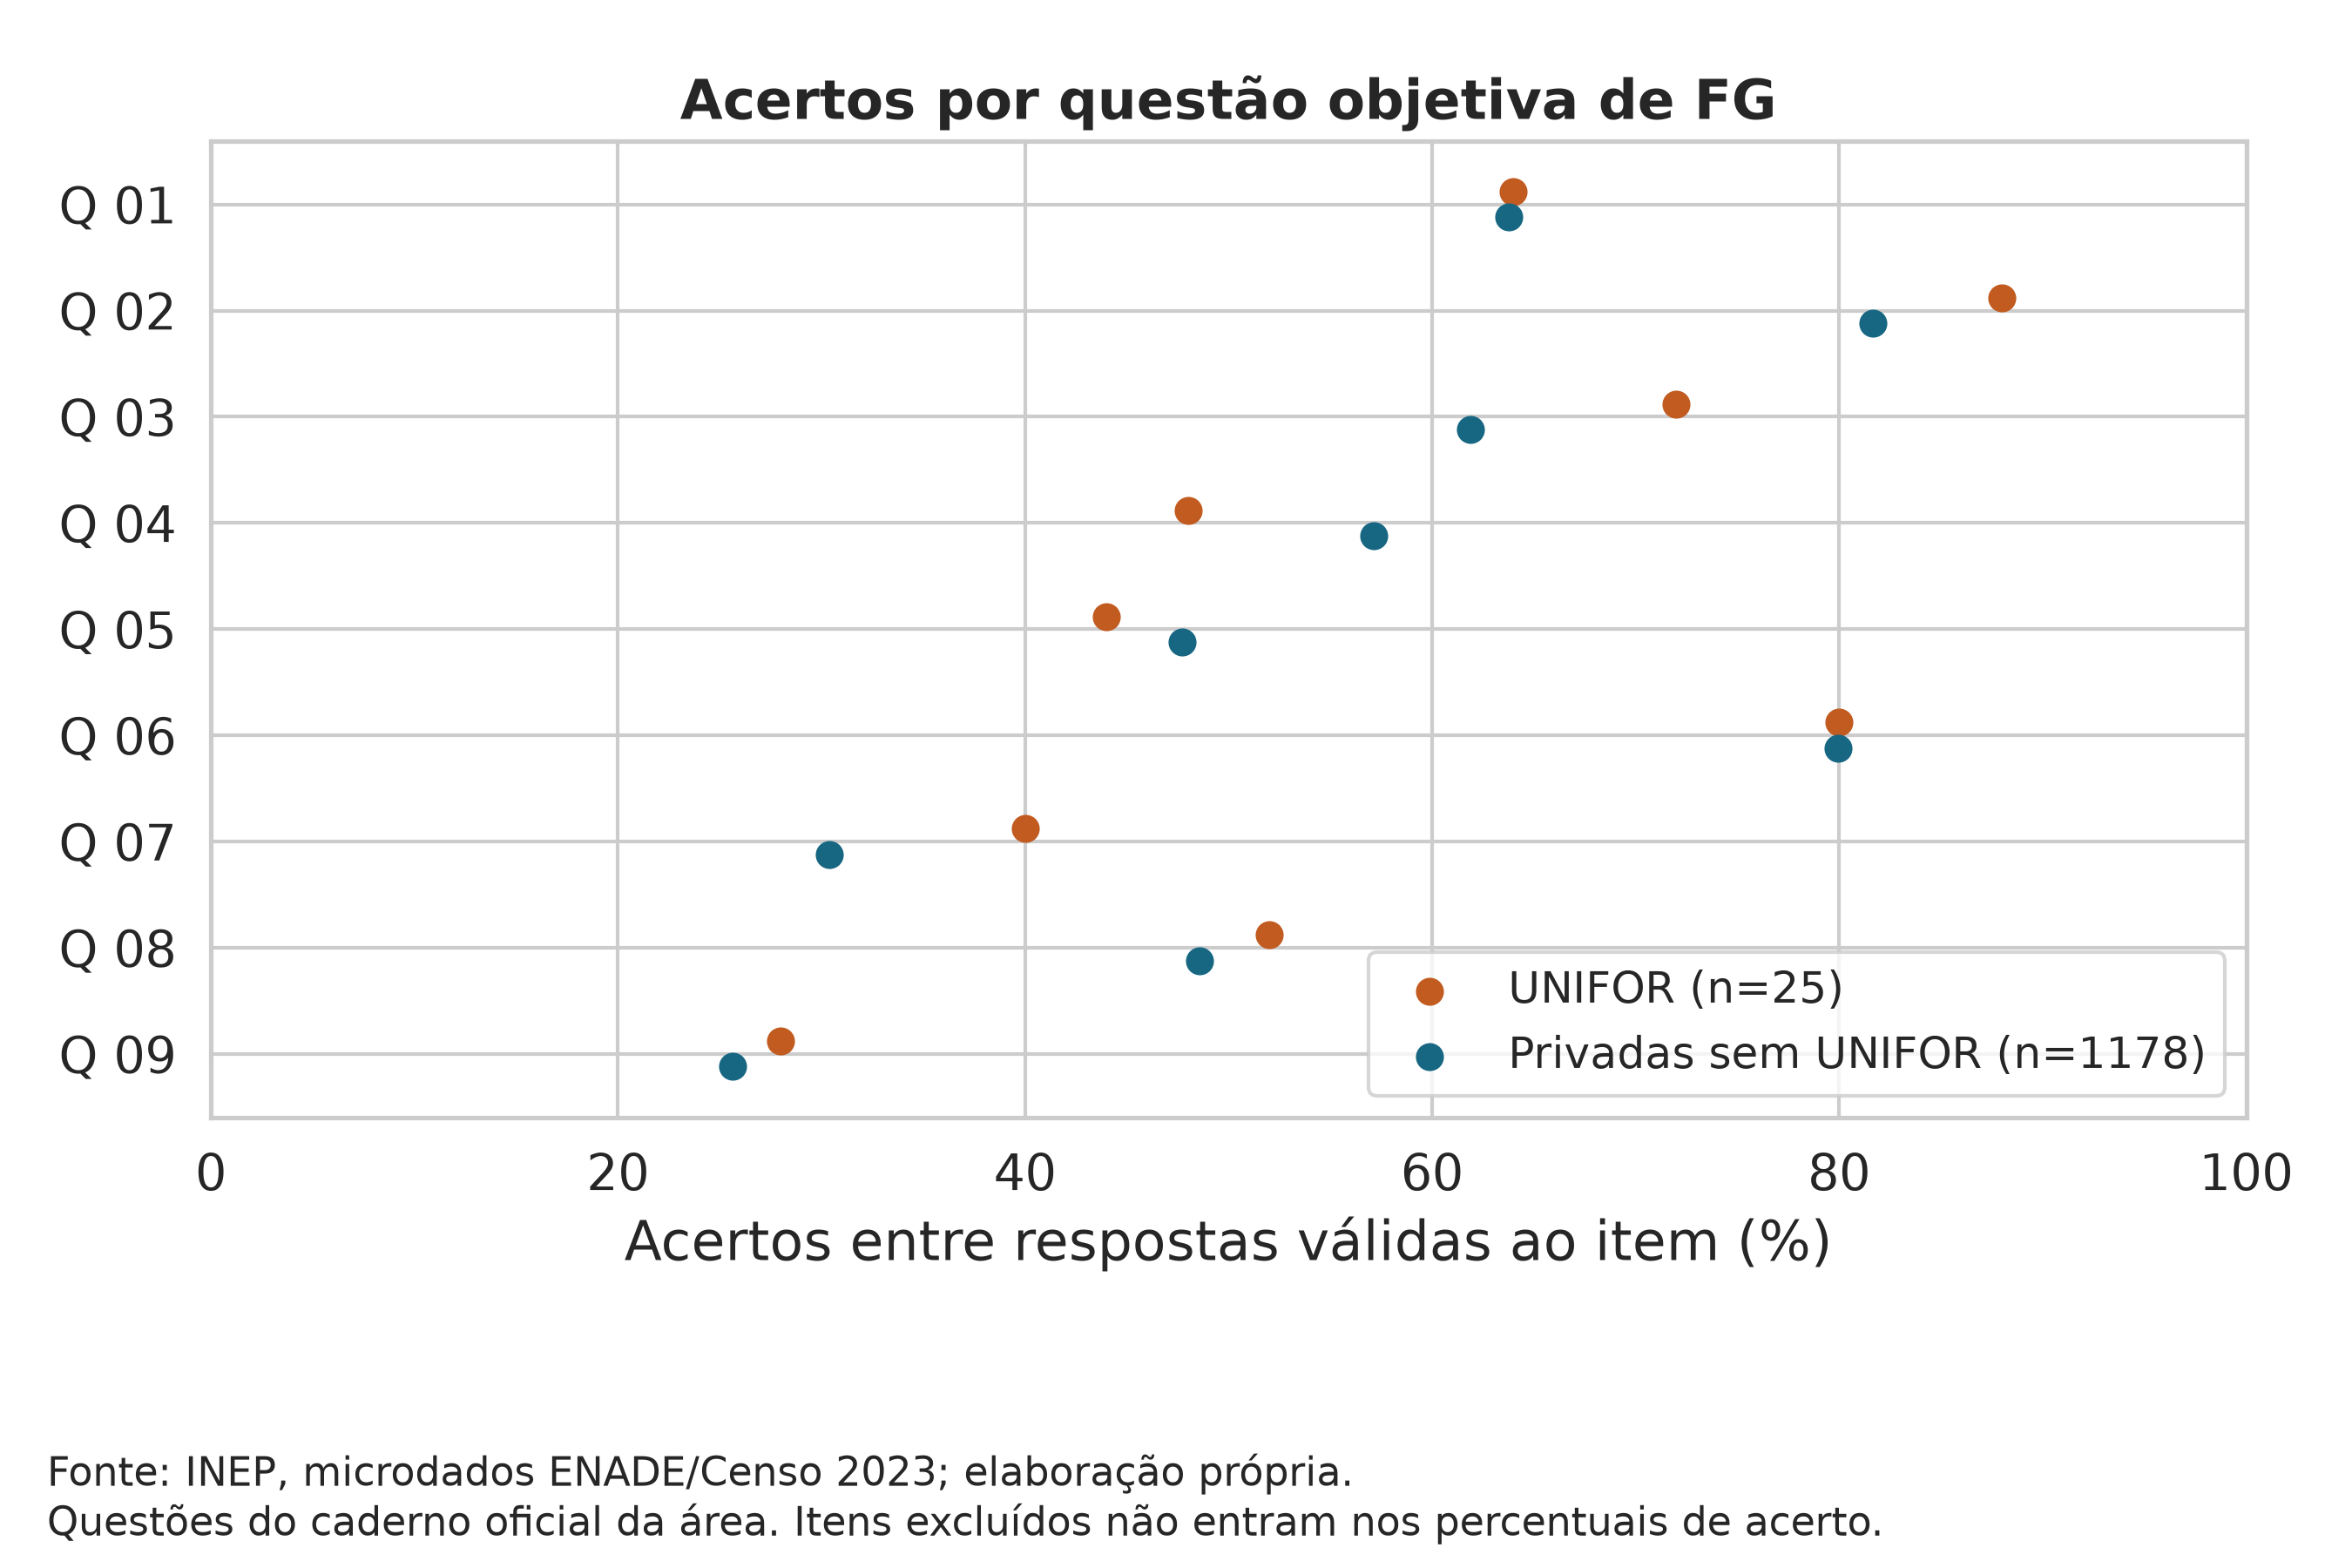

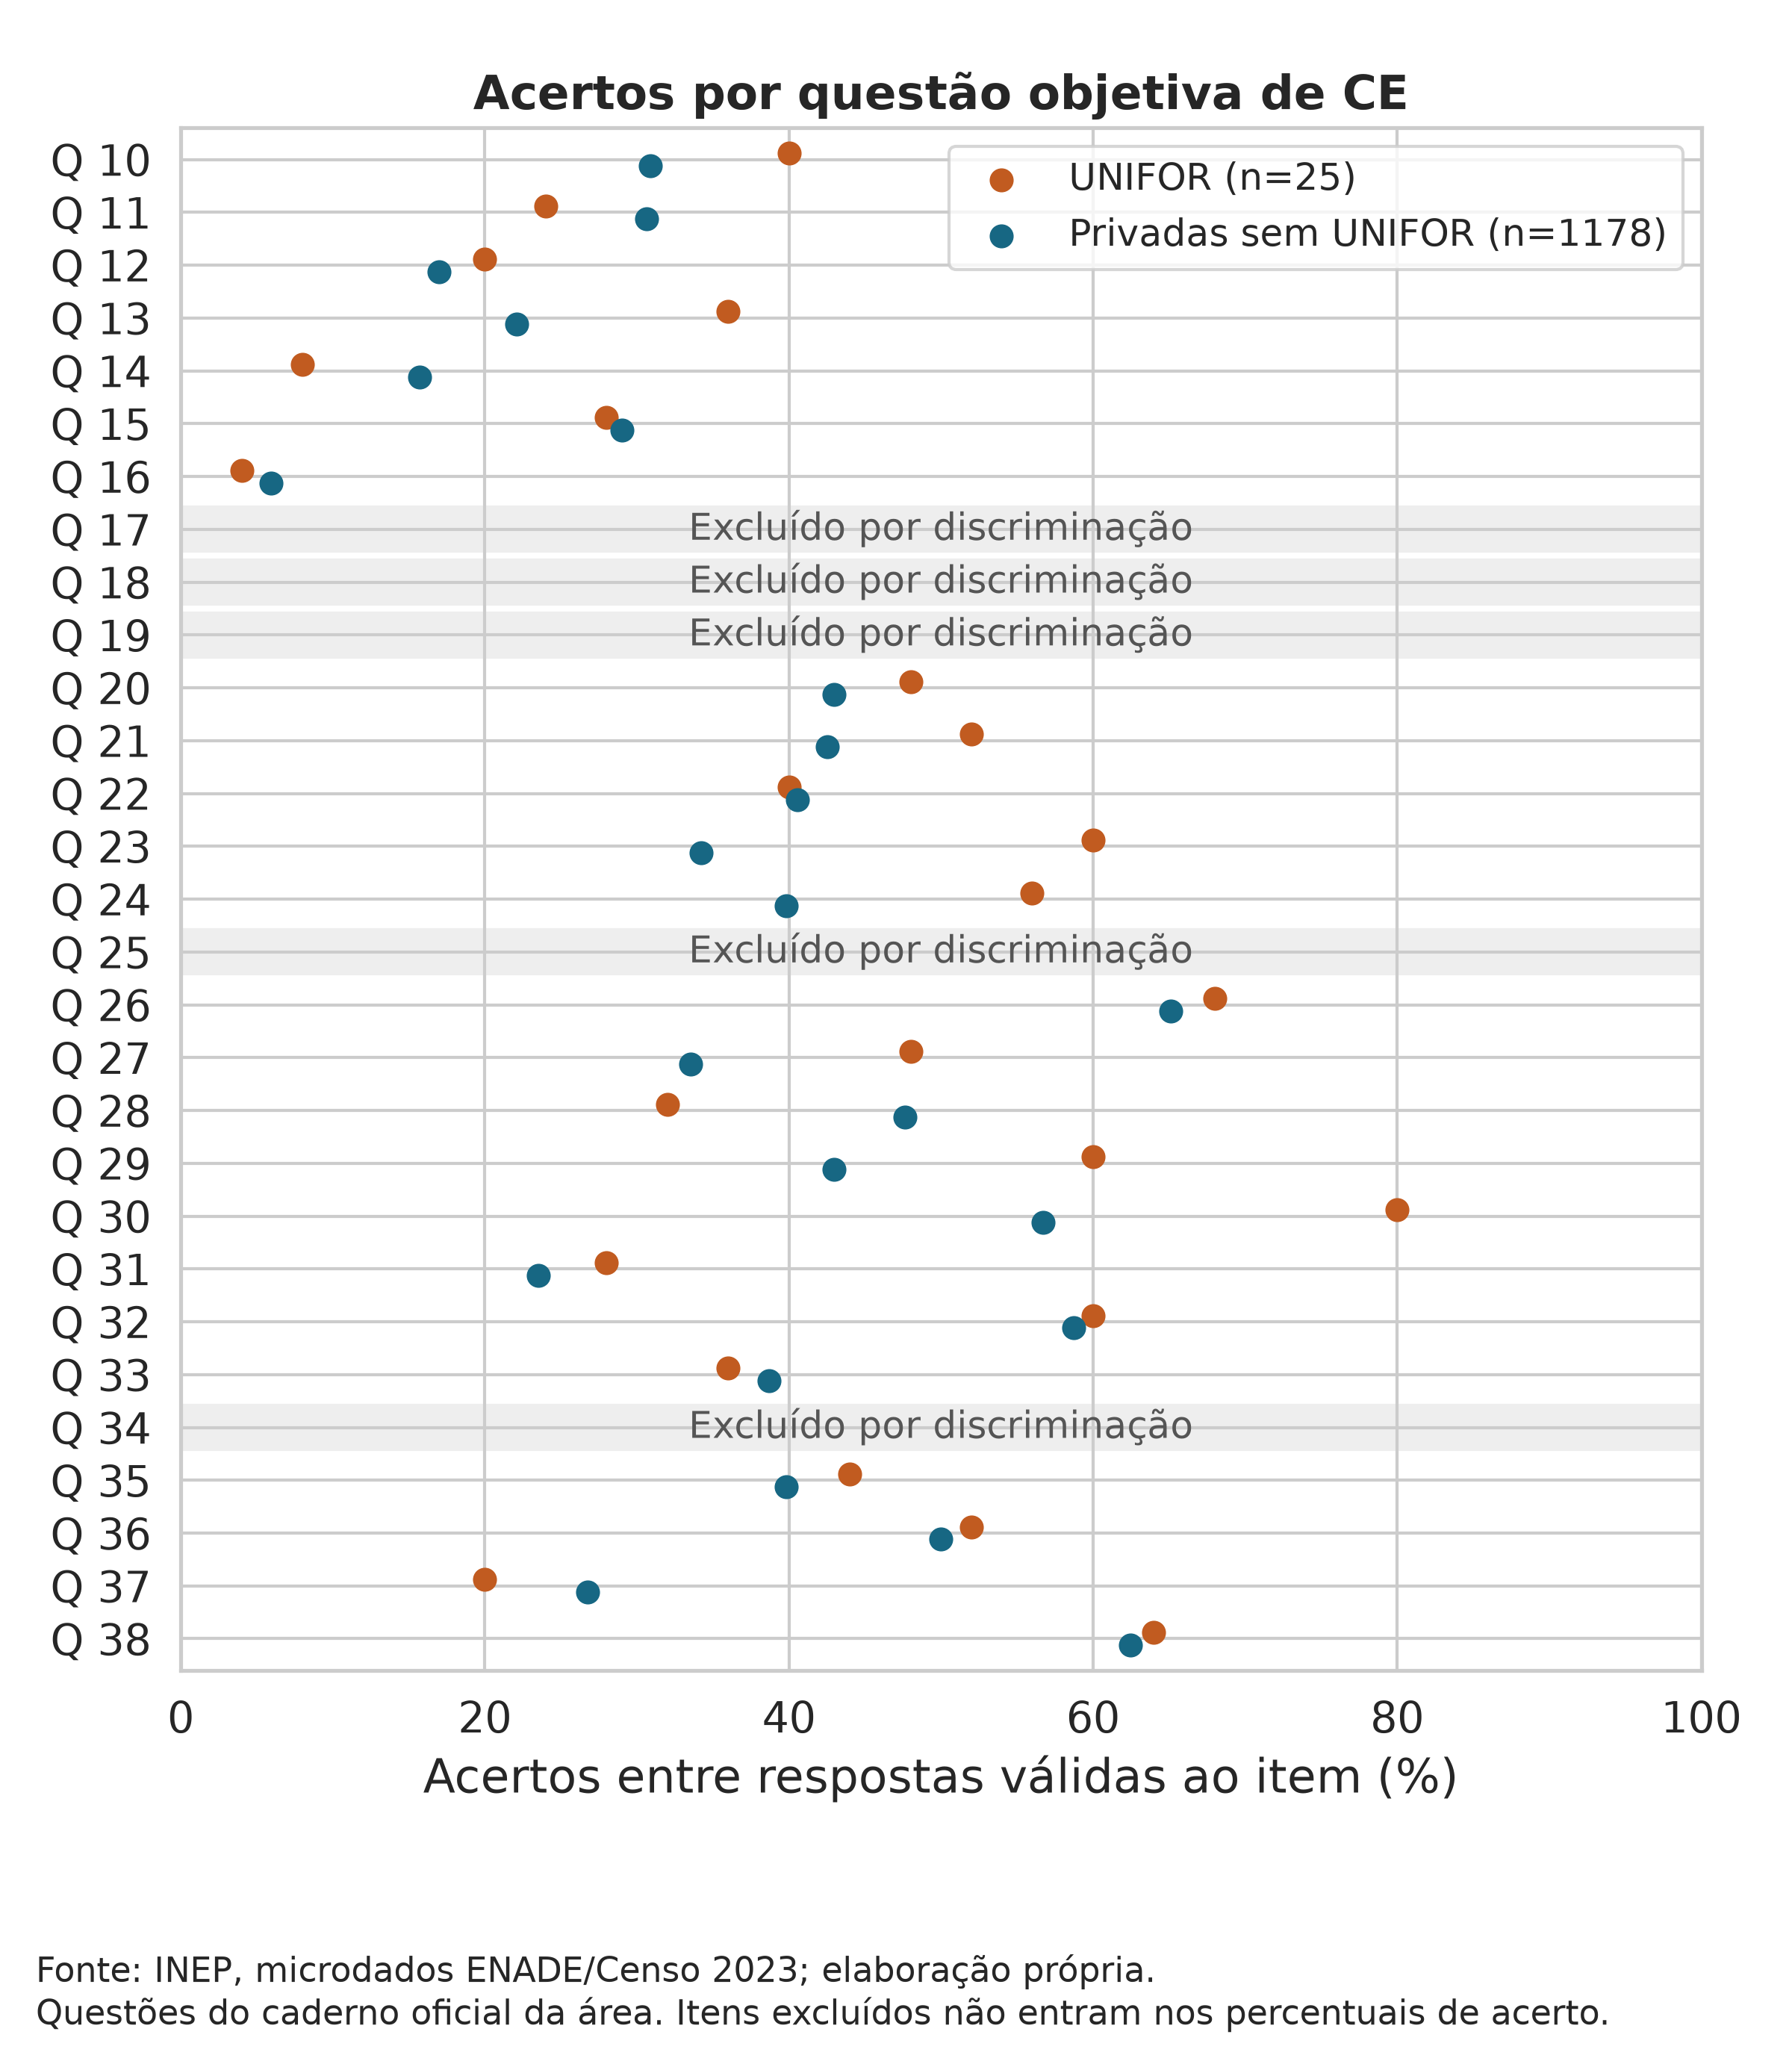

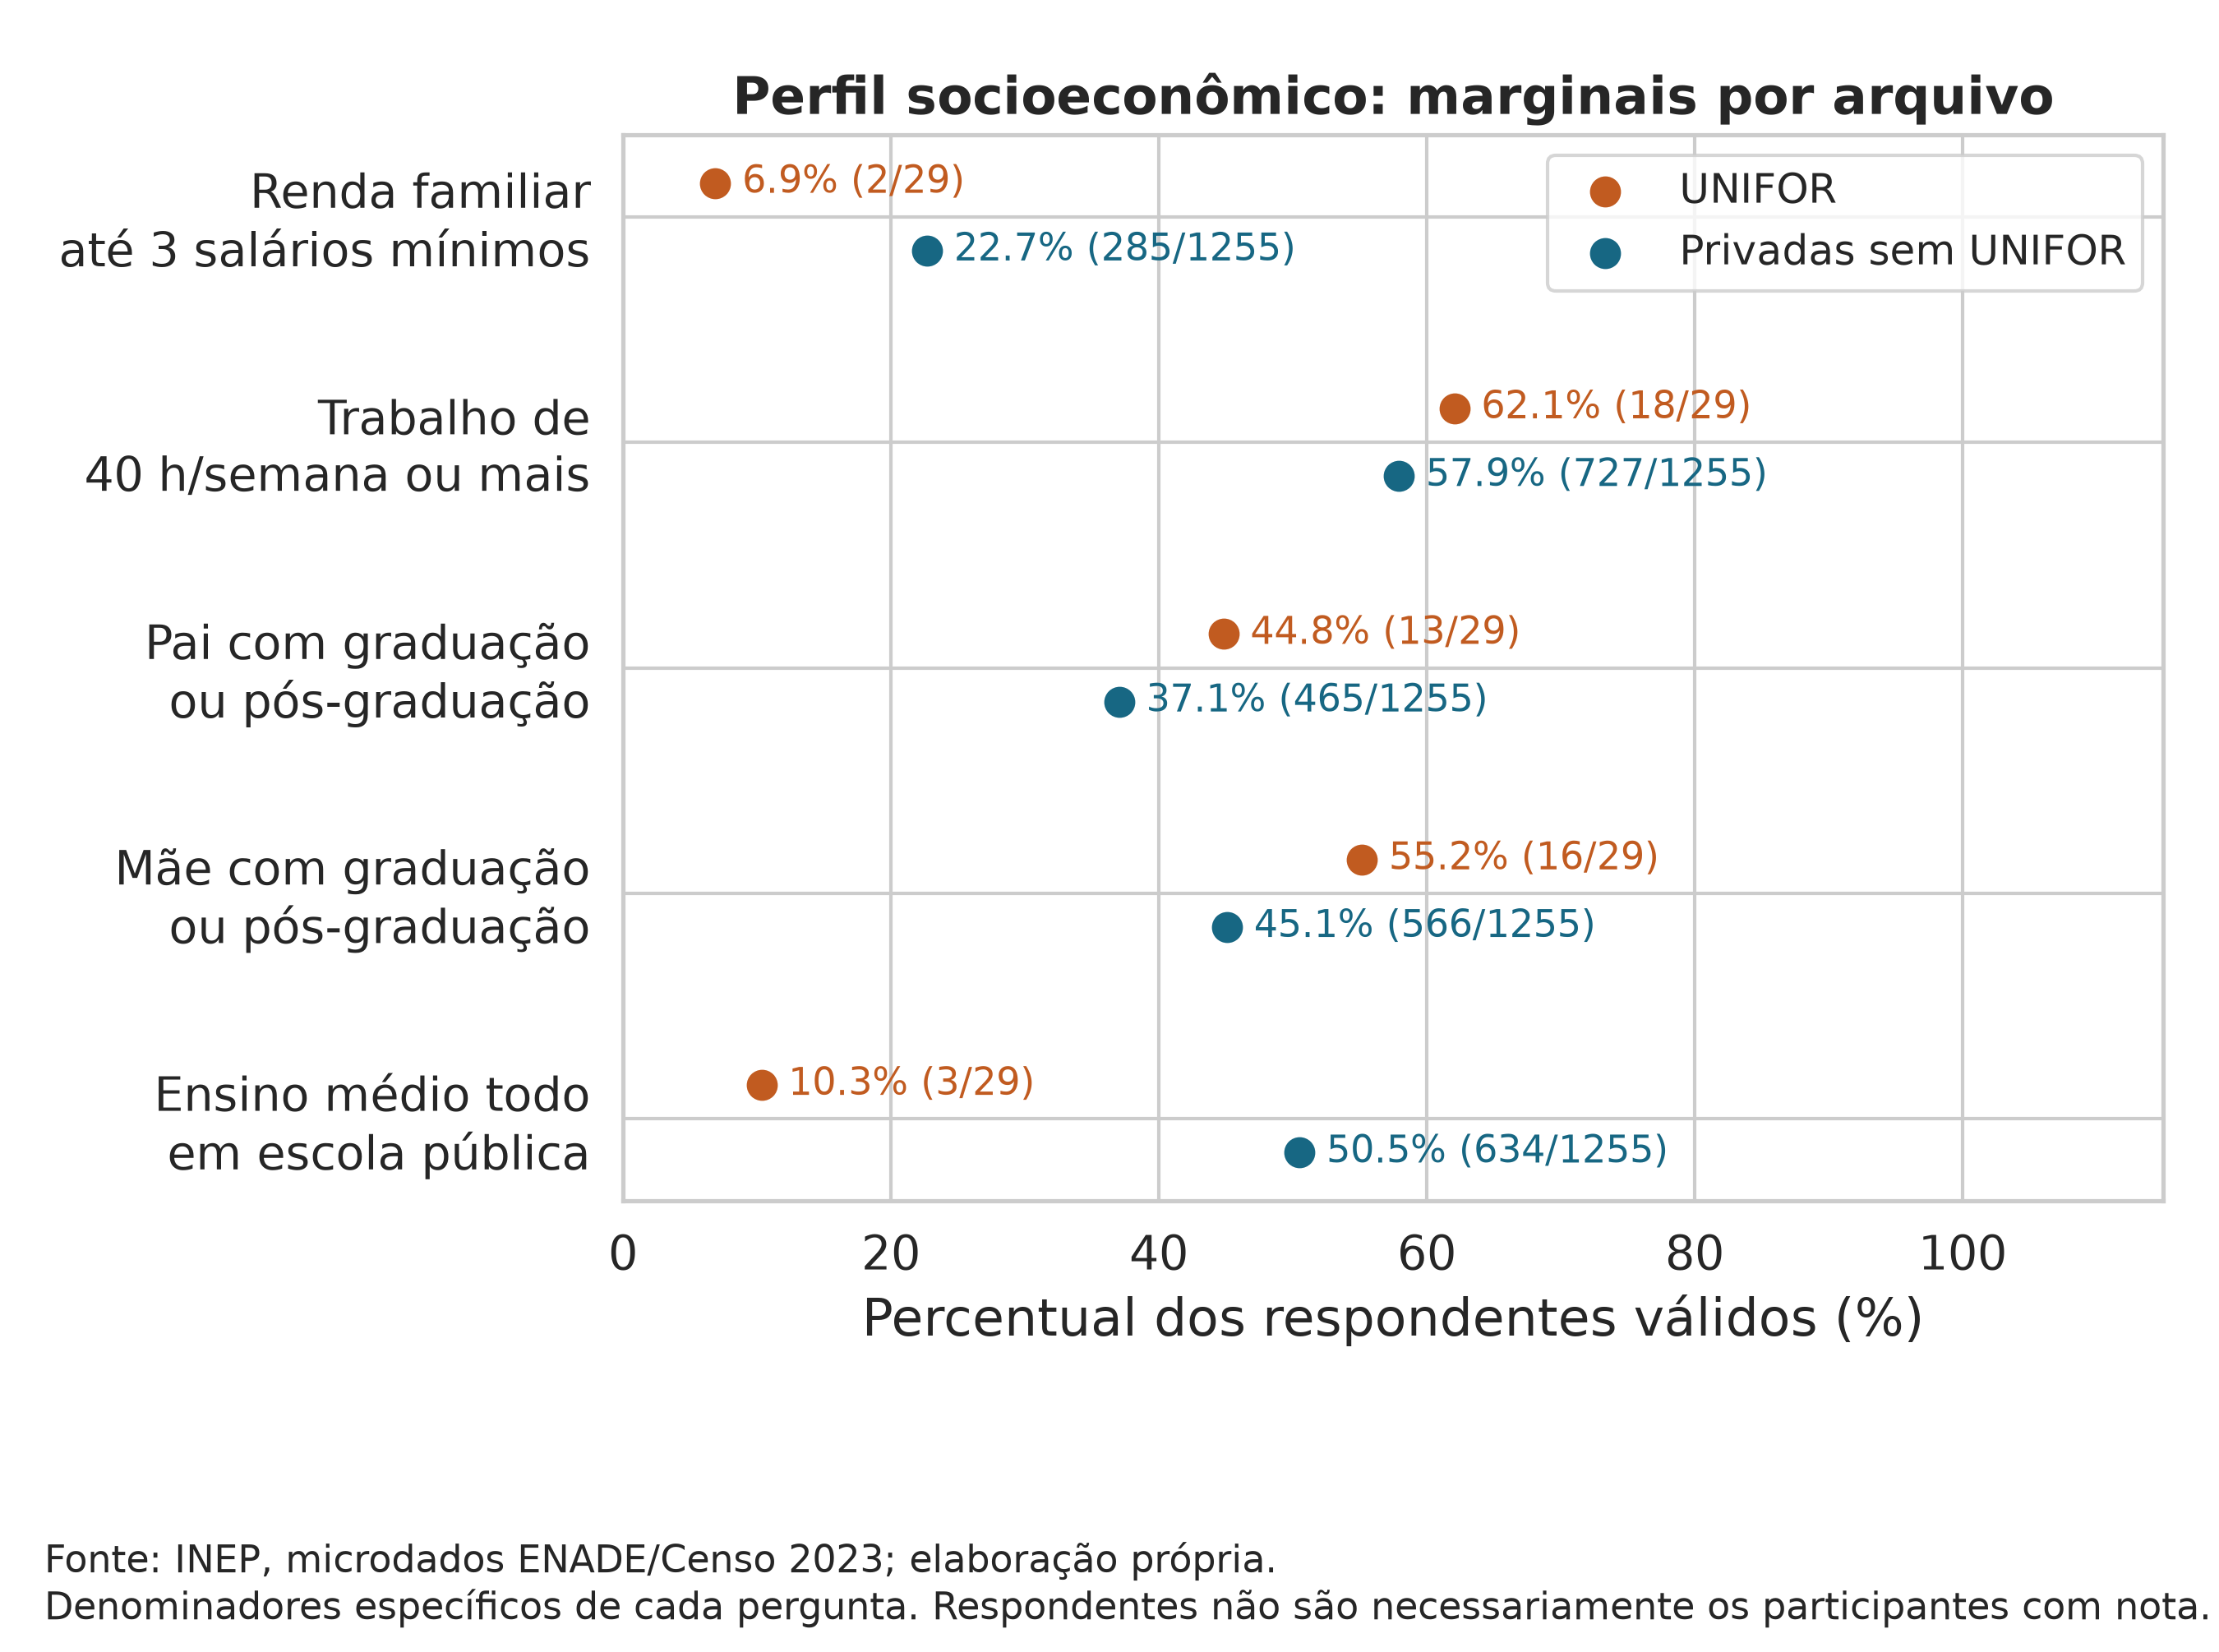

In [12]:
for nome in aprofundado['validacao']['graficos']:
    if nome.endswith('.png'):
        display(Image(filename=str(ROOT / 'resultados/graficos' / nome)))

## Verificação independente e bônus
A auditoria relê os ZIPs com `csv`, `Counter` e `statistics`. Hashes protegem originais, entradas e saídas. Os diretórios de 2021 só têm `.gitkeep`; não houve download de microdados. A paginação depende de compilação LaTeX: dez blocos editoriais não comprovam dez páginas.

In [13]:
from verificar_aprofundamento_2023 import verify_deep
verificacao = verify_deep(ROOT)
print(aprofundado['validacao']['bonus_2021'])

{
  "status": "aprovado",
  "origem": "releitura ZIP oficial via csv, Counter e statistics",
  "verificacoes": {
    "denominadores": 6,
    "estatisticas": 210,
    "correlacoes_individuais": 5,
    "itens": 925,
    "proporcoes_marginais": 12390,
    "indicadores": 50,
    "ecologicas": 10
  },
  "total_verificacoes": 13596,
  "hashes_entradas_saidas_brutos_conferidos": true,
  "sem_pareamento_individual_entre_arquivos": true
}
{'arquivos_locais': {'enade_2021': [], 'censo_2021': []}, 'status': 'pendente_sem_microdados'}
